# CardioGuía RAG · ACA 1 · Computación en la Nube para Sistemas Inteligentes

**Ingesta, fragmentación, embeddings y almacenamiento vectorial en la nube para consultar guías clínicas cardiovasculares**

| | |
|---|---|
| **Institución** | Corporación Unificada Nacional de Educación Superior (CUN) · Especialización en Inteligencia Artificial |
| **Asignatura** | Computación en la Nube para Sistemas Inteligentes · Docente: Hamilton Rivera Flor |
| **Grupo 13** | Daimer Cardona Rojas · Cristhian Eduardo Cortes Martha · Juan Manuel Guerrero Tupaz · Luis Alberto Ospina Delgado · Jhonny Mauricio Rosero Carpio |
| **Pilar** | Salud · Dataset base: UCI Heart Disease (Cleveland, 303 pacientes) |
| **Stack** | Google Colab · DuckDB · PyMuPDF · LangChain Text Splitters · Multilingual-E5 (Hugging Face, Sentence-Transformers) · Qdrant Cloud (capa gratuita) · comparación con OpenAI `text-embedding-3-large` |

## Situación problema

En Colombia, las enfermedades isquémicas del corazón son la primera causa de muerte: 92,7 defunciones por cada 100.000 habitantes en 2025, según cifras preliminares del DANE (2026). Las recomendaciones para prevenirlas y tratarlas existen, pero están repartidas en guías de práctica clínica en PDF de decenas de páginas. Cuando un médico, un estudiante o un paciente necesita una respuesta concreta ("¿desde qué cifra se considera hipertensión?", "¿qué hago si siento dolor en el pecho?"), buscar palabra por palabra en esos documentos es lento y falla con los sinónimos: quien escribe "tensión alta" no encuentra "hipertensión arterial".

En el ACA de Aprendizaje Automático construimos **CardioRiesgo**, un modelo que estima la probabilidad de enfermedad coronaria con 13 datos clínicos del dataset UCI Heart Disease. Este proyecto lo complementa: un modelo dice **qué tan alto es el riesgo**; las guías clínicas dicen **qué hacer con ese riesgo**. Aquí construimos la base de conocimiento en la nube que permitirá, en el ACA 2, que un asistente RAG responda con fragmentos verificables de esas guías.

**Pregunta orientadora.** ¿Cómo estructurar e implementar una canalización de datos no estructurados en la nube, con una base de datos vectorial serverless y un modelo de embeddings, que permita indexar y recuperar por significado información clínica cardiovascular con alta precisión, costo cero y baja latencia?

**Objetivo general.** Diseñar e implementar la arquitectura cloud de ingesta, fragmentación, generación de embeddings y almacenamiento semántico de un corpus de guías clínicas cardiovasculares en Qdrant Cloud, integrado con los metadatos del dataset UCI Heart Disease, y validar la recuperación semántica con métricas cuantitativas.

**Objetivos específicos**

1. Aprovisionar una base SQL (DuckDB) para el dataset estructurado y un clúster vectorial gratuito en Qdrant Cloud, con credenciales en variables de entorno.
2. Reunir y limpiar un corpus de 3 guías oficiales del Ministerio de Salud de Colombia y asociar cada fragmento a las variables clínicas del dataset.
3. Elegir con datos el tamaño de los fragmentos, comparando tres configuraciones de chunking.
4. Vectorizar los fragmentos con un modelo abierto y multilingüe (Multilingual-E5), cargarlos por lotes sin salir de la capa gratuita y compararlo con un modelo comercial (OpenAI).
5. Validar la búsqueda semántica (Top-k, similitud coseno, Hit@k y MRR) y demostrar consultas filtradas e híbridas SQL + vector.

## Arquitectura de la solución

![Arquitectura cloud de CardioGuía RAG](attachment:arquitectura.png)

| Paso | Qué hace | Herramienta |
|---|---|---|
| 1. Aprovisionamiento | Base SQL para los 303 pacientes y clúster vectorial en la nube | DuckDB · Qdrant Cloud (Free tier, 1 GB) |
| 2. Ingesta | Lectura de 3 guías clínicas en PDF, limpieza y metadatos | PyMuPDF |
| 3. Chunking | Fragmentación recursiva por párrafos y oraciones, con solapamiento | LangChain `RecursiveCharacterTextSplitter` |
| 4. Embeddings | Cada fragmento se convierte en un vector de 768 números | `intfloat/multilingual-e5-base` (Hugging Face); comparación: OpenAI `text-embedding-3-large` |
| 5. Búsqueda semántica | La pregunta se vectoriza y se recuperan los Top-k fragmentos más parecidos por coseno | Qdrant `query_points` con filtros por metadatos |

**Cómo ejecutar este notebook.** En Google Colab, abra el panel 🔑 *Secrets* y cree `QDRANT_URL` y `QDRANT_API_KEY` (con acceso del notebook activado). El modelo de embeddings es abierto y no necesita clave; `OPENAI_API_KEY` es opcional y solo se usa si falta algún vector de la comparación en la caché. Fuera de Colab, copie `.env.example` como `.env` y escriba allí los valores. Suba a Colab el archivo comprimido del proyecto (`ACA1_Nube_G13.zip`) o las carpetas `corpus/` y `datos/`, y ejecute todo (*Entorno de ejecución → Ejecutar todas*). Los embeddings quedan guardados en `cache/`, así que una segunda ejecución no los vuelve a calcular.

## 1. Entorno de trabajo y credenciales

Instalamos solo lo que falte. Todas las librerías son de código abierto y los servicios en la nube se usan en su capa gratuita.

In [1]:
import importlib.metadata as md_paquetes
import subprocess
import sys

REQUISITOS = {  # paquete pip: versión mínima probada
    "openai": "1.40.0",
    "qdrant-client": "1.12.0",
    "duckdb": "1.1.0",
    "pymupdf": "1.24.0",
    "langchain-text-splitters": "0.3.0",
    "python-dotenv": "1.0.0",
}


def _version(paquete):
    try:
        return md_paquetes.version(paquete)
    except md_paquetes.PackageNotFoundError:
        return None


def _menor(a, b):
    convertir = lambda v: tuple(int(x) for x in v.split(".")[:3] if x.isdigit())
    return convertir(a) < convertir(b)


por_instalar = [f"{p}>={v}" for p, v in REQUISITOS.items() if _version(p) is None or _menor(_version(p), v)]
if por_instalar:
    print("Instalando:", ", ".join(por_instalar))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", *por_instalar])
for p in REQUISITOS:
    print(f"{p:26s} {_version(p)}")

Instalando: qdrant-client>=1.12.0, pymupdf>=1.24.0, langchain-text-splitters>=0.3.0
openai                     2.54.0
qdrant-client              1.20.0
duckdb                     1.3.2
pymupdf                    2.0
langchain-text-splitters   1.1.3
python-dotenv              1.2.4


In [2]:
import hashlib
import json
import os
import re
import time
import unicodedata
import uuid
import warnings
import zipfile
from collections import Counter, deque
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from IPython.display import HTML, display
from langchain_text_splitters import RecursiveCharacterTextSplitter

warnings.filterwarnings("ignore", message=".*Payload indexes have no effect.*")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})

SEMILLA = 42
BASE = Path.cwd()

# Si en Colab se subió el comprimido del proyecto, se descomprime aquí
if not (BASE / "corpus").exists():
    for zip_proyecto in sorted(BASE.glob("ACA1_Nube_G13*.zip")):
        with zipfile.ZipFile(zip_proyecto) as z:
            z.extractall(BASE)
        raiz = next((p for p in BASE.iterdir() if p.is_dir() and (p / "corpus").exists()), None)
        if raiz is not None:
            os.chdir(raiz)
            BASE = Path.cwd()
        print("Proyecto descomprimido desde", zip_proyecto.name)
        break

CARPETA_CORPUS = BASE / "corpus"
CARPETA_DATOS = BASE / "datos"
CARPETA_CACHE = BASE / "cache"
CARPETA_SALIDAS = BASE / "salidas"
for carpeta in (CARPETA_CACHE, CARPETA_SALIDAS):
    carpeta.mkdir(exist_ok=True)

# Parámetros del pipeline
MODELO_EMBEDDINGS = os.getenv("EMBEDDING_MODEL", "intfloat/multilingual-e5-base")   # modelo abierto de Hugging Face
MODELO_COMPARACION = "text-embedding-3-large"   # modelo comercial de OpenAI, solo para comparar (sección 8)
DIMENSION = 768                      # E5-base produce 768 dimensiones; a OpenAI se le piden las mismas
COLECCION = "guias_cardio_g13"       # colección en Qdrant Cloud
RECREAR_COLECCION = True             # borra y vuelve a crear la colección en cada ejecución completa
TOP_K = 3
print("Carpeta del proyecto:", BASE)

Proyecto descomprimido desde ACA1_Nube_G13.zip
Carpeta del proyecto: /content/ACA1_Nube_G13


### Gestión segura de credenciales

Las claves **nunca** se escriben en el código. El notebook las lee de variables de entorno:

- **Google Colab:** panel 🔑 *Secrets* (`QDRANT_URL`, `QDRANT_API_KEY` y, opcional, `OPENAI_API_KEY`).
- **Jupyter local o VS Code:** archivo `.env` en la carpeta del proyecto (plantilla en `.env.example`). El `.gitignore` impide subirlo a GitHub.

Solo mostramos si cada variable está configurada, nunca su valor.

In [3]:
from dotenv import load_dotenv

load_dotenv(BASE / ".env")          # entorno local: lee .env si existe

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import userdata
    for nombre in ("OPENAI_API_KEY", "QDRANT_URL", "QDRANT_API_KEY"):
        if not os.getenv(nombre):
            try:
                valor = userdata.get(nombre)
            except Exception:
                valor = None
            if valor:
                os.environ[nombre] = valor

def _limpio(nombre):
    """Lee la variable y quita espacios, saltos de línea y comillas que se cuelan al copiar y pegar."""
    valor = (os.getenv(nombre) or "").strip().strip('"').strip("'").strip()
    return valor or None


OPENAI_API_KEY = _limpio("OPENAI_API_KEY")
QDRANT_URL = _limpio("QDRANT_URL")
QDRANT_API_KEY = _limpio("QDRANT_API_KEY")
if OPENAI_API_KEY and not OPENAI_API_KEY.startswith("sk-"):
    print("Aviso: la OPENAI_API_KEY no parece una clave de OpenAI (suelen empezar por 'sk-').")
if QDRANT_URL and not QDRANT_URL.startswith("http"):
    QDRANT_URL = "https://" + QDRANT_URL

display(pd.DataFrame([
    {"Variable": "OPENAI_API_KEY", "Estado": "configurada" if OPENAI_API_KEY else "falta",
     "Uso": "opcional: solo si falta en la caché algún vector de la comparación con OpenAI"},
    {"Variable": "QDRANT_URL", "Estado": "configurada" if QDRANT_URL else "falta",
     "Uso": "dirección del clúster en Qdrant Cloud"},
    {"Variable": "QDRANT_API_KEY", "Estado": "configurada" if QDRANT_API_KEY else "falta",
     "Uso": "clave de acceso al clúster"},
]))
if not QDRANT_URL:
    print("Sin QDRANT_URL: se usará una base Qdrant en memoria, solo para pruebas.")

,Variable,Estado,Uso
0,OPENAI_API_KEY,configurada,opcional: solo si falta en la caché algún vector de la comparación con OpenAI
1,QDRANT_URL,configurada,dirección del clúster en Qdrant Cloud
2,QDRANT_API_KEY,configurada,clave de acceso al clúster


## 2. Dataset base estructurado en una base SQL (DuckDB)

**UCI Heart Disease (Cleveland)**: 303 pacientes de la Cleveland Clinic con 13 datos clínicos y el resultado de una angiografía coronaria (Janosi et al., 1988). Es el mismo dataset del proyecto de Aprendizaje Automático. Lo guardamos en **DuckDB**, una base SQL analítica que corre dentro del notebook y se guarda en un solo archivo (`salidas/cardio_uci.duckdb`).

Además de la tabla de pacientes creamos un **diccionario de variables**: para cada dato clínico dice qué es, desde qué valor es una alerta y con qué términos aparece en las guías. Ese diccionario es el puente entre el dataset y los documentos: con él cada fragmento de texto queda etiquetado con las variables clínicas de las que habla.

In [4]:
COLUMNAS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
            "exang", "oldpeak", "slope", "ca", "thal", "num"]
URL_UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

ruta_uci = CARPETA_DATOS / "processed.cleveland.data"
if ruta_uci.exists():
    crudo, fuente_datos = pd.read_csv(ruta_uci, header=None, names=COLUMNAS, na_values="?"), "copia local (datos/)"
else:
    crudo, fuente_datos = pd.read_csv(URL_UCI, header=None, names=COLUMNAS, na_values="?"), "UCI Machine Learning Repository"

pacientes = crudo.copy()
pacientes.insert(0, "paciente_id", range(1, len(pacientes) + 1))
pacientes["enfermedad"] = (pacientes["num"] > 0).astype(int)
ETIQUETAS = {
    "sex": {0: "Mujer", 1: "Hombre"},
    "cp": {1: "Angina típica", 2: "Angina atípica", 3: "Dolor no anginoso", 4: "Asintomático"},
    "restecg": {0: "Normal", 1: "Anomalía ST-T", 2: "Hipertrofia ventricular izquierda"},
    "thal": {3: "Normal", 6: "Defecto fijo", 7: "Defecto reversible"},
}
pacientes["sexo"] = pacientes["sex"].map(ETIQUETAS["sex"])
pacientes["tipo_dolor"] = pacientes["cp"].map(ETIQUETAS["cp"])
pacientes["ecg_reposo"] = pacientes["restecg"].map(ETIQUETAS["restecg"])
pacientes["talio"] = pacientes["thal"].map(ETIQUETAS["thal"])

print(f"Fuente: {fuente_datos} · {len(pacientes)} pacientes · {pacientes[COLUMNAS].isna().sum().sum()} valores faltantes")
pacientes.head()

Fuente: copia local (datos/) · 303 pacientes · 6 valores faltantes


,paciente_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,enfermedad,sexo,tipo_dolor,ecg_reposo,talio
0,1,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0,Hombre,Angina típica,Hipertrofia ventricular izquierda,Defecto fijo
1,2,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1,Hombre,Asintomático,Hipertrofia ventricular izquierda,Normal
2,3,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1,Hombre,Asintomático,Hipertrofia ventricular izquierda,Defecto reversible
3,4,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0,Hombre,Dolor no anginoso,Normal,Normal
4,5,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0,Mujer,Angina atípica,Hipertrofia ventricular izquierda,Normal


In [5]:
# Diccionario de variables: descripción, regla de alerta y términos con que aparecen en las guías.
# Los términos se escriben sin tildes porque el texto se compara normalizado.
DICCIONARIO = [
    {"variable": "age", "nombre": "Edad", "descripcion": "Edad del paciente en años",
     "alerta": None, "terminos": [r"\bedad\b", r"\bmayores? de \d+ anos\b", r"\badultos? mayores?\b"]},
    {"variable": "sex", "nombre": "Sexo", "descripcion": "Sexo biológico (0 = mujer, 1 = hombre)",
     "alerta": None, "terminos": [r"\bsexo\b", r"\bhombres?\b", r"\bmujer(es)?\b"]},
    {"variable": "cp", "nombre": "Tipo de dolor torácico",
     "descripcion": "1 angina típica, 2 atípica, 3 dolor no anginoso, 4 asintomático",
     "alerta": "cp IN (1, 2)", "terminos": [r"\bdolor (toracico|en el pecho|precordial)\b", r"\bangina\b",
                                            r"\bopresion en el pecho\b", r"\bdolor de pecho\b"]},
    {"variable": "trestbps", "nombre": "Presión arterial en reposo", "descripcion": "Presión sistólica en reposo (mm Hg)",
     "alerta": "trestbps >= 140", "terminos": [r"\bpresion arterial\b", r"\btension arterial\b", r"\bhipertens\w*",
                                               r"\bmm ?hg\b", r"\bpresion sistolica\b", r"\bantihipertensiv\w*"]},
    {"variable": "chol", "nombre": "Colesterol sérico", "descripcion": "Colesterol total en sangre (mg/dl)",
     "alerta": "chol >= 240", "terminos": [r"\bcolesterol\b", r"\bldl\b", r"\bhdl\b", r"\blipid\w*",
                                           r"\bdislipidemi\w*", r"\bestatinas?\b", r"\btrigliceridos\b"]},
    {"variable": "fbs", "nombre": "Glucemia en ayunas > 120 mg/dl", "descripcion": "1 si la glucosa en ayunas supera 120 mg/dl",
     "alerta": "fbs = 1", "terminos": [r"\bglucosa\b", r"\bglucemia\b", r"\bdiabet\w*", r"\bazucar en (la )?sangre\b"]},
    {"variable": "restecg", "nombre": "Electrocardiograma en reposo", "descripcion": "0 normal, 1 anomalía ST-T, 2 hipertrofia ventricular",
     "alerta": "restecg IN (1, 2)", "terminos": [r"\belectrocardiogram\w*", r"\becg\b", r"\bekg\b",
                                                 r"\bhipertrofia ventricular\b"]},
    {"variable": "thalach", "nombre": "Frecuencia cardiaca máxima", "descripcion": "Pulso máximo en la prueba de esfuerzo (lpm)",
     "alerta": None, "terminos": [r"\bfrecuencia cardiaca\b", r"\bpulso\b", r"\blatidos\b"]},
    {"variable": "exang", "nombre": "Angina inducida por ejercicio", "descripcion": "1 si hubo dolor torácico durante la prueba de esfuerzo",
     "alerta": "exang = 1", "terminos": [r"\bangina (de|al|con el|durante el) (esfuerzo|ejercicio)\b",
                                         r"\bprueba de esfuerzo\b", r"\b(esfuerzo|ejercicio) fisico\b"]},
    {"variable": "oldpeak", "nombre": "Depresión del ST", "descripcion": "Descenso del segmento ST con el ejercicio (mm)",
     "alerta": "oldpeak >= 1", "terminos": [r"\bsegmento st\b", r"\b(depresion|elevacion|desnivel|supradesnivel|infradesnivel) del (segmento )?st\b",
                                            r"\bcon elevacion del st\b", r"\bsin elevacion del st\b"]},
    {"variable": "ca", "nombre": "Vasos coloreados (fluoroscopia)", "descripcion": "Arterias principales con estenosis visibles (0-3)",
     "alerta": "ca >= 1", "terminos": [r"\bangiografi\w*", r"\bcoronariografi\w*", r"\bcateterismo\w*",
                                       r"\barterias? coronarias?\b", r"\bangioplasti\w*", r"\bstent\w*"]},
    {"variable": "thal", "nombre": "Gammagrafía con talio", "descripcion": "3 normal, 6 defecto fijo, 7 defecto reversible",
     "alerta": "thal IN (6, 7)", "terminos": [r"\btalio\b", r"\bgammagrafi\w*", r"\bperfusion miocardica\b"]},
    {"variable": "enfermedad", "nombre": "Enfermedad coronaria (objetivo)", "descripcion": "1 si la angiografía mostró una arteria estrechada > 50 %",
     "alerta": "enfermedad = 1", "terminos": [r"\benfermedad coronaria\b", r"\bsindrome coronario\b", r"\binfarto\w*",
                                              r"\bisquemi\w*", r"\bcardiopatia isquemica\b", r"\bobstrucci\w* (de|en) (la|las|una) arteria\w*"]},
]
diccionario = pd.DataFrame([{**d, "terminos": " | ".join(d["terminos"])} for d in DICCIONARIO])

con = duckdb.connect(str(CARPETA_SALIDAS / "cardio_uci.duckdb"))
con.register("pacientes_df", pacientes)
con.register("diccionario_df", diccionario)
con.execute("CREATE OR REPLACE TABLE pacientes AS SELECT * FROM pacientes_df")
con.execute("CREATE OR REPLACE TABLE diccionario_variables AS SELECT * FROM diccionario_df")
con.unregister("pacientes_df")
con.unregister("diccionario_df")
print(con.execute("SELECT table_name, estimated_size AS filas FROM duckdb_tables() ORDER BY table_name").df().to_string(index=False))
diccionario[["variable", "nombre", "descripcion", "alerta"]]

           table_name  filas
diccionario_variables     13
            pacientes    303


,variable,nombre,descripcion,alerta
0,age,Edad,Edad del paciente en años,None
1,sex,Sexo,"Sexo biológico (0 = mujer, 1 = hombre)",None
2,cp,Tipo de dolor torácico,"1 angina típica, 2 atípica, 3 dolor no anginoso, 4 asintomático","cp IN (1, 2)"
3,trestbps,Presión arterial en reposo,Presión sistólica en reposo (mm Hg),trestbps >= 140
4,chol,Colesterol sérico,Colesterol total en sangre (mg/dl),chol >= 240
5,fbs,Glucemia en ayunas > 120 mg/dl,1 si la glucosa en ayunas supera 120 mg/dl,fbs = 1
6,restecg,Electrocardiograma en reposo,"0 normal, 1 anomalía ST-T, 2 hipertrofia ventricular","restecg IN (1, 2)"
7,thalach,Frecuencia cardiaca máxima,Pulso máximo en la prueba de esfuerzo (lpm),None
8,exang,Angina inducida por ejercicio,1 si hubo dolor torácico durante la prueba de esfuerzo,exang = 1
9,oldpeak,Depresión del ST,Descenso del segmento ST con el ejercicio (mm),oldpeak >= 1


In [6]:
consultas_sql = {
    "Prevalencia por sexo": """
        SELECT sexo, COUNT(*) AS pacientes, ROUND(100 * AVG(enfermedad), 1) AS pct_con_enfermedad
        FROM pacientes GROUP BY sexo ORDER BY sexo""",
    "Prevalencia por grupo de edad": """
        SELECT CASE WHEN age < 45 THEN '29-44' WHEN age < 55 THEN '45-54' WHEN age < 65 THEN '55-64' ELSE '65-77' END AS grupo_edad,
               COUNT(*) AS pacientes, ROUND(100 * AVG(enfermedad), 1) AS pct_con_enfermedad
        FROM pacientes GROUP BY grupo_edad ORDER BY grupo_edad""",
    "Factores de riesgo según diagnóstico": """
        SELECT CASE enfermedad WHEN 1 THEN 'Con enfermedad' ELSE 'Sin enfermedad' END AS diagnostico,
               COUNT(*) AS pacientes,
               ROUND(100 * AVG(CASE WHEN trestbps >= 140 THEN 1 ELSE 0 END), 1) AS pct_presion_140,
               ROUND(100 * AVG(CASE WHEN chol >= 240 THEN 1 ELSE 0 END), 1) AS pct_colesterol_240,
               ROUND(100 * AVG(fbs), 1) AS pct_glucemia_alta,
               ROUND(100 * AVG(exang), 1) AS pct_angina_ejercicio
        FROM pacientes GROUP BY diagnostico ORDER BY diagnostico""",
}
resultados_sql = {}
for titulo, sql in consultas_sql.items():
    resultados_sql[titulo] = con.execute(sql).df()
    print(titulo)
    display(resultados_sql[titulo])

Prevalencia por sexo


,sexo,pacientes,pct_con_enfermedad
0,Hombre,206,55.3
1,Mujer,97,25.8


Prevalencia por grupo de edad


,grupo_edad,pacientes,pct_con_enfermedad
0,29-44,55,25.5
1,45-54,88,34.1
2,55-64,119,63.0
3,65-77,41,48.8


Factores de riesgo según diagnóstico


,diagnostico,pacientes,pct_presion_140,pct_colesterol_240,pct_glucemia_alta,pct_angina_ejercicio
0,Con enfermedad,139,38.8,57.6,15.8,54.7
1,Sin enfermedad,164,26.8,46.3,14.0,14.0


## 3. Corpus documental: ingesta y limpieza

La guía del ACA exige complementar el dataset con 2 a 3 documentos no estructurados del sector. Elegimos **tres guías de práctica clínica del Ministerio de Salud de Colombia, en su versión para pacientes**: son oficiales, están en español, tienen un lenguaje claro y son cortas (para no exceder la capa gratuita). Cada una cubre variables del dataset:

| Documento | Páginas con contenido | Variables del dataset que trata |
|---|---|---|
| Síndrome coronario agudo, guía para pacientes y cuidadores (2013) | 8 a 26 | dolor torácico y angina, electrocardiograma y segmento ST, angiografía y cateterismo, colesterol |
| Hipertensión arterial primaria, guía para pacientes y familiares (2013) | 11 a 15 | presión arterial (cifras, diagnóstico, prevención y tratamiento), edad, sexo |
| Dislipidemias, guía para pacientes y familiares (2014) | 9 a 17 | colesterol LDL y HDL, triglicéridos, estatinas, diabetes |

**Extracción.** PyMuPDF entrega cada línea con su tamaño de letra y su posición. Con eso:

- Se reconocen los **títulos** por tamaño de letra (11 a 13 puntos frente a 9 a 10 del cuerpo) y se usan como metadato de sección. En la guía de síndrome coronario los títulos están en una columna lateral partidos en varias líneas; se vuelven a unir.
- Se quitan **encabezados y pies de página** (letra pequeña en los bordes de la hoja), números de página y los **recuadros destacados** que repiten frases del texto.
- Se ordenan los bloques en orden de lectura, se unen las palabras partidas con guion y las líneas de un mismo párrafo, y las **tablas** se convierten en oraciones ("Grupo de alimentos: Lácteos; Recomendados: …").
- Se excluyen portada, créditos e índice, y las secciones que solo listan **preguntas sugeridas para el médico**: no contienen respuestas y competirían con los fragmentos que sí las tienen.

In [7]:
# Corpus: tres guías oficiales del Ministerio de Salud de Colombia, versión para pacientes. Los PDF van en corpus/.
# "paginas" es el rango con contenido: se excluyen portada, créditos, autores e índice.
CORPUS = [
    {"doc_id": "SCA", "archivo": "minsalud_2013_sindrome_coronario_agudo_pacientes.pdf", "paginas": (8, 26),
     "titulo": "Guía de síndrome coronario agudo para pacientes y cuidadores (GPC-2013-17)",
     "titulo_corto": "Síndrome coronario agudo", "institucion": "MinSalud · Colciencias", "anio": 2013,
     "color": "#c2410c", "url": "https://www.quindio.gov.co/home/docs/items/item_196/GPC_Ptes_SCA.pdf"},
    {"doc_id": "HTA", "archivo": "minsalud_2013_hipertension_arterial_pacientes.pdf", "paginas": (11, 15),
     "titulo": "Guía de práctica clínica hipertensión arterial primaria, para pacientes y familiares (Guía No. 18)",
     "titulo_corto": "Hipertensión arterial", "institucion": "MinSalud · Colciencias", "anio": 2013,
     "color": "#1f6fb2", "url": "https://www.minsalud.gov.co/sites/rid/Lists/BibliotecaDigital/RIDE/INEC/IETS/GPC_Ptes_HTA.pdf"},
    {"doc_id": "DIS", "archivo": "minsalud_2014_dislipidemia_pacientes.pdf", "paginas": (9, 17),
     "titulo": "Guía de práctica clínica de dislipidemias en la población mayor de 18 años, para pacientes y familiares (Guía No. 27)",
     "titulo_corto": "Dislipidemias (colesterol)", "institucion": "MinSalud · Colciencias", "anio": 2014,
     "color": "#0f766e", "url": "https://www.minsalud.gov.co/sites/rid/Lists/BibliotecaDigital/RIDE/INEC/IETS/GPC-Dislipidemia-pacientes.pdf"},
]
for doc in CORPUS:
    doc["url_descarga"] = doc["url"]     # si falta el PDF en corpus/, se descarga de la fuente oficial
pd.DataFrame(CORPUS)[["doc_id", "titulo_corto", "institucion", "anio", "paginas", "archivo"]]

,doc_id,titulo_corto,institucion,anio,paginas,archivo
0,SCA,Síndrome coronario agudo,MinSalud · Colciencias,2013,"(8, 26)",minsalud_2013_sindrome_coronario_agudo_pacientes.pdf
1,HTA,Hipertensión arterial,MinSalud · Colciencias,2013,"(11, 15)",minsalud_2013_hipertension_arterial_pacientes.pdf
2,DIS,Dislipidemias (colesterol),MinSalud · Colciencias,2014,"(9, 17)",minsalud_2014_dislipidemia_pacientes.pdf


In [8]:
TAM_TITULO = 10.8      # puntos: en estas guías los títulos van en 11-13 pt y el cuerpo en 9-10 pt
SECCIONES_SIN_RESPUESTAS = ("preguntas que usted podria",)   # listas de preguntas sugeridas para el médico
GUION_SUAVE = chr(0x00AD)
CORTE_PAGINA = chr(0x2063)      # marca invisible: la última palabra de la página sigue en la siguiente
VINETA = chr(0x2022)
REEMPLAZOS = {chr(0xFB01): "fi", chr(0xFB02): "fl", chr(0xF0B7): VINETA, "\t": " "}


def normalizar(texto):
    """Minúsculas y sin tildes, para comparar texto sin importar acentos."""
    texto = unicodedata.normalize("NFKD", texto.lower())
    return "".join(c for c in texto if not unicodedata.combining(c))


def _dentro(caja, rect, margen=2):
    x0, y0, x1, y1 = caja
    return x0 >= rect[0] - margen and y0 >= rect[1] - margen and x1 <= rect[2] + margen and y1 <= rect[3] + margen


def _tablas(pagina):
    """Tablas de la página como texto: una oración por fila ('columna: valor; ...')."""
    salida = []
    palabras = pagina.get_text("words")
    for tabla in pagina.find_tables().tables:
        if tabla.row_count < 3 or tabla.col_count < 2:
            continue
        filas = []
        for fila in tabla.rows:
            celdas = []
            for celda in fila.cells:
                if celda is None:
                    celdas.append("")
                    continue
                dentro = sorted((w for w in palabras if _dentro(w[:4], celda)), key=lambda w: (w[5], w[6], w[7]))
                texto = " ".join(w[4] for w in dentro).replace(GUION_SUAVE + " ", "").replace(GUION_SUAVE, "")
                celdas.append(re.sub(r"\s+", " ", texto).strip())
            filas.append(celdas)
        encabezado, cuerpo = filas[0], filas[1:]
        oraciones = []
        for f in cuerpo:
            partes = [f"{encabezado[j]}: {v.rstrip('.')}" if encabezado[j] else v.rstrip(".")
                      for j, v in enumerate(f) if v]
            if partes:
                oraciones.append("; ".join(partes) + ".")
        salida.append({"bbox": tuple(tabla.bbox), "filas": oraciones})
    return salida


def _bloques(pagina):
    """Bloques de texto de la página, sin encabezados/pies, recuadros destacados ni tablas."""
    alto = pagina.rect.height
    tablas = _tablas(pagina)
    bloques = []
    for bloque in pagina.get_text("dict")["blocks"]:
        if "lines" not in bloque or any(_dentro(bloque["bbox"], t["bbox"], 4) for t in tablas):
            continue
        lineas = []
        for linea in bloque["lines"]:
            spans = [s for s in linea["spans"] if s["text"].strip()]
            # Recuadros con letra blanca del tamaño del cuerpo: repiten frases del texto (citas destacadas)
            spans = [s for s in spans if not (s["color"] == 0xFFFFFF and s["size"] < TAM_TITULO)]
            if not spans:
                continue
            texto = re.sub(r"[ \t]+", " ", "".join(s["text"] for s in spans)).strip()
            tam = max(s["size"] for s in spans)
            y0 = linea["bbox"][1]
            if tam <= 8.5 and (y0 < 0.09 * alto or y0 > 0.91 * alto):      # encabezado o pie de página
                continue
            if re.fullmatch(r"\d{1,3}", texto):
                continue
            tipo = "capital" if tam >= 20 and len(texto) == 1 else ("titulo" if tam >= TAM_TITULO and len(texto) > 1 else "cuerpo")
            lineas.append({"texto": texto, "tipo": tipo, "y": y0})
        if lineas:
            bloques.append({"x": bloque["bbox"][0], "y": bloque["bbox"][1], "lineas": lineas})
    for t in tablas:
        filas = [{"texto": f, "tipo": "tabla", "y": t["bbox"][1] + k} for k, f in enumerate(t["filas"])]
        bloques.append({"x": t["bbox"][0], "y": t["bbox"][1], "lineas": filas})
    return bloques


def _continua(anterior, siguiente):
    """¿El texto siguiente continúa la oración del anterior (por ejemplo, texto que rodea una imagen)?"""
    anterior = anterior.rstrip(CORTE_PAGINA)
    return bool(anterior) and not re.search(r"[.:;?!»”\")]\s*$", anterior) and bool(re.match(r"[a-záéíóúñü(]", siguiente))


def _limpiar(texto):
    for viejo, nuevo in REEMPLAZOS.items():
        texto = texto.replace(viejo, nuevo)
    texto = re.sub(GUION_SUAVE + r"\s*$", CORTE_PAGINA, texto)                  # palabra partida al final de la página
    texto = re.sub(GUION_SUAVE + r"\s*\n\s*", "", texto).replace(GUION_SUAVE, "")
    texto = re.sub(r"(\w)-\s*$", r"\1" + CORTE_PAGINA, texto)
    texto = re.sub(r"(\w)-\n(?=[a-záéíóúñü])", r"\1", texto)                     # palabras partidas al final de línea
    texto = re.sub(VINETA + r"\s*\n\s*", VINETA + " ", texto)
    texto = re.sub(r"\n(?!" + VINETA + ")", " ", texto)                          # líneas de un mismo párrafo
    texto = re.sub(r"\s*" + VINETA + r"\s*", "\n" + VINETA + " ", texto).lstrip("\n")
    return re.sub(r"[ ]{2,}", " ", texto).strip()


def _piezas_pagina(pagina):
    """Lista ordenada de piezas ('titulo' | 'parrafo', texto) de una página."""
    titulos, cuerpo = [], []
    for b in _bloques(pagina):
        for l in b["lineas"]:
            (titulos if l["tipo"] == "titulo" else cuerpo).append({**l, "by": b["y"], "bx": b["x"]})
    titulos.sort(key=lambda l: l["y"])
    # Orden de lectura: por bloque (de arriba abajo y de izquierda a derecha), conservando las líneas del bloque
    cuerpo.sort(key=lambda l: (round(l["by"] / 3), l["bx"], l["y"]))

    grupos = []                      # títulos partidos en varias líneas (columna lateral)
    for l in titulos:
        if grupos and l["y"] - grupos[-1]["y_fin"] < 22:
            grupos[-1]["texto"] += " " + l["texto"]
            grupos[-1]["y_fin"] = l["y"]
        else:
            grupos.append({"y": l["y"], "y_fin": l["y"], "texto": l["texto"]})

    parrafos, previo = [], None
    for l in cuerpo:
        if previo is not None and previo["tipo"] == "capital":           # letra capital + resto de la palabra
            parrafos[-1]["texto"] += l["texto"]
            previo = {**l, "tipo": "cuerpo"}
            continue
        mismo_bloque = previo is not None and previo["by"] == l["by"] and previo["bx"] == l["bx"]
        nuevo = (l["tipo"] == "tabla" or previo is None or previo["tipo"] == "tabla"
                 or not mismo_bloque or l["y"] - previo["y"] > 17)
        if nuevo and previo is not None and not mismo_bloque and l["tipo"] != "tabla" and parrafos \
                and _continua(parrafos[-1]["texto"], l["texto"]):
            nuevo = False                                                   # el bloque sigue la oración anterior
        if nuevo:
            parrafos.append({"y": l["y"], "texto": l["texto"], "tabla": l["tipo"] == "tabla"})
        else:
            parrafos[-1]["texto"] += "\n" + l["texto"]
        previo = l

    # Cada título va antes del primer párrafo que empieza a su altura o más abajo (nunca en medio de un párrafo)
    piezas, i = [], 0
    for p in parrafos:
        while i < len(grupos) and grupos[i]["y"] <= p["y"] + 6:
            piezas.append(("titulo", re.sub(r"\s+", " ", grupos[i]["texto"]).strip()))
            i += 1
        piezas.append(("parrafo", p["texto"] if p["tabla"] else _limpiar(p["texto"])))
    piezas.extend(("titulo", re.sub(r"\s+", " ", g["texto"]).strip()) for g in grupos[i:])
    return piezas


def extraer_documento(ruta, paginas_contenido):
    """Páginas del rango de contenido como texto limpio, con los títulos detectados por tamaño de letra.
    Omite las secciones que solo listan preguntas sugeridas para el médico (no contienen respuestas)."""
    inicio, fin = paginas_contenido
    paginas, omitidas, excluyendo = [], [], False
    with pymupdf.open(ruta) as pdf:
        total = len(pdf)
        for n in range(inicio, fin + 1):
            pagina = pdf[n - 1]
            texto, titulos = "", []
            for tipo, contenido in _piezas_pagina(pagina):
                if tipo == "titulo":
                    excluyendo = normalizar(contenido).startswith(SECCIONES_SIN_RESPUESTAS)
                    if excluyendo:
                        omitidas.append({"pagina": n, "seccion": contenido})
                        continue
                    titulos.append(contenido)
                    texto += "\n\n" + contenido + "\n\n"
                elif not excluyendo:
                    texto += "\n\n" + contenido
            texto = re.sub(r"\n{3,}", "\n\n", texto).strip()
            paginas.append({"pagina": n, "texto": texto, "titulos": titulos, "cruda": pagina.get_text("text")})
    return paginas, omitidas, total


def unir_paginas(paginas):
    """Une el texto de las páginas y devuelve (texto, posición inicial de cada página). Si una página termina
    a mitad de palabra u oración y la siguiente sigue en minúscula, se unen sin abrir un párrafo nuevo."""
    texto, inicios = "", []
    for p in paginas:
        contenido = p["texto"]
        if texto.endswith(CORTE_PAGINA) and re.match(r"[a-záéíóúñü]", contenido):
            texto = texto[:-1]
        elif texto and _continua(texto, contenido):
            texto = texto.rstrip(CORTE_PAGINA) + " "
        elif texto:
            texto = texto.rstrip(CORTE_PAGINA) + "\n\n"
        inicios.append(len(texto))
        texto += contenido
    return texto.replace(CORTE_PAGINA, ""), inicios

In [9]:
documentos = []
for meta in CORPUS:
    ruta = CARPETA_CORPUS / meta["archivo"]
    if not ruta.exists() and meta.get("url_descarga"):
        import requests
        print("Descargando", meta["archivo"], "desde la fuente oficial")
        respuesta = requests.get(meta["url_descarga"], timeout=60, headers={"User-Agent": "Mozilla/5.0"})
        respuesta.raise_for_status()
        CARPETA_CORPUS.mkdir(exist_ok=True)
        ruta.write_bytes(respuesta.content)
    paginas, omitidas, total_paginas = extraer_documento(ruta, meta["paginas"])
    texto, _ = unir_paginas(paginas)
    documentos.append({**meta, "ruta": ruta, "paginas_texto": paginas, "secciones_omitidas": omitidas,
                       "total_paginas": total_paginas, "texto": texto})

resumen_corpus = pd.DataFrame([{
    "doc_id": d["doc_id"], "documento": d["titulo_corto"], "año": d["anio"], "páginas PDF": d["total_paginas"],
    "páginas indexadas": f"{d['paginas'][0]}-{d['paginas'][1]}", "palabras": len(d["texto"].split()),
    "caracteres": len(d["texto"]), "tokens_est": round(len(d["texto"]) / 4),
    "títulos": sum(len(p["titulos"]) for p in d["paginas_texto"]),
    "secciones omitidas": len(d["secciones_omitidas"]), "MB": round(d["ruta"].stat().st_size / 1e6, 2),
} for d in documentos])
display(resumen_corpus)
print(f"Total: {resumen_corpus['palabras'].sum():,} palabras · ~{resumen_corpus['tokens_est'].sum():,} tokens estimados "
      "(1 token ≈ 4 caracteres en español)".replace(",", "."))
for d in documentos:
    for o in d["secciones_omitidas"]:
        print(f"Omitida ({d['doc_id']}, p. {o['pagina']}): {o['seccion']} (solo lista preguntas para el médico)")

,doc_id,documento,año,páginas PDF,páginas indexadas,palabras,caracteres,tokens_est,títulos,secciones omitidas,MB
0,SCA,Síndrome coronario agudo,2013,27,8-26,3982,25457,6364,24,3,2.08
1,HTA,Hipertensión arterial,2013,16,11-15,1206,7676,1919,7,0,3.11
2,DIS,Dislipidemias (colesterol),2014,18,9-17,1980,13208,3302,15,0,3.21


Total: 7.168 palabras · ~11.585 tokens estimados (1 token ≈ 4 caracteres en español)
Omitida (SCA, p. 13): Preguntas qué usted podría hacer acerca de un tratamiento (solo lista preguntas para el médico)
Omitida (SCA, p. 24): Preguntas que Usted podría hacerse acerca de los medicamentos (solo lista preguntas para el médico)
Omitida (SCA, p. 25): Preguntas que Usted podría hacer al ser dado de alta del hospital (solo lista preguntas para el médico)


In [10]:
# Antes y después de la limpieza, en una página de ejemplo
doc_ej = next(d for d in documentos if d["doc_id"] == "HTA")
pag_ej = doc_ej["paginas_texto"][1]
print(f"{doc_ej['titulo_corto']} · página {pag_ej['pagina']}\n")
print("── Texto tal como sale del PDF ──")
print(pag_ej["cruda"][:1000])
print("\n── Texto limpio (títulos detectados: " + "; ".join(pag_ej["titulos"]) + ") ──")
print(pag_ej["texto"][:1000])

Hipertensión arterial · página 12

── Texto tal como sale del PDF ──
Para pacientes y familiares
12 | CINETS
Por estas razones es importante conocer y controlar las cifras de presión 
arterial. Se ha comprobado que  el control adecuado  reduce la probabi­
lidad de tener complicaciones de salud. 
¿Quiénes están en mayor riesgo de tener 
hipertensión arterial?
Las personas que más frecuentemente desarrollan hipertensión arterial son:
•	
Mayores de 35 años
•	
Personas con sobrepeso
•	
Quienes no realizan ejercicio físico regularmente
•	
Las personas con familiares que hayan sufrido de hipertensión arterial
•	
Quienes fuman regularmente
Si usted tiene una o varias de estas características, es aún más importante 
que conozca sus valores de presión arterial. Su médico le dirá los pasos a 
seguir de acuerdo a los valores que encuentre.
¿Cómo se previene la hipertensión arterial?
En la mayoría de personas, la hipertensión arterial se puede prevenir dis­
minuyendo el consumo de sal (sodio) en l

## 4. Pipeline de chunking

Un PDF completo no cabe con precisión en un solo vector: si se vectoriza todo junto, el vector "promedia" temas distintos y la búsqueda pierde detalle. Por eso se corta en **fragmentos (chunks)**. Usamos `RecursiveCharacterTextSplitter`, que intenta cortar primero entre párrafos, luego entre líneas, luego entre oraciones y solo al final entre palabras, para no partir una idea por la mitad. Un **solapamiento** entre fragmentos vecinos evita perder la oración que queda justo en el corte.

¿De qué tamaño? No hay un valor universal, así que **lo decidimos con datos**: generamos tres configuraciones y, en la sección 6, medimos cuál recupera mejor las respuestas de un conjunto de preguntas de prueba.

| Configuración | Tamaño (caracteres) | Solapamiento | Tokens aproximados |
|---|---|---|---|
| Pequeño | 500 | 75 (15 %) | ~125 |
| Mediano | 1.000 | 150 (15 %) | ~250 |
| Grande | 2.000 | 200 (10 %) | ~500, el valor de referencia de la guía del proyecto |

Cada fragmento conserva sus **metadatos**: documento, institución, año, páginas, sección y las **variables clínicas del dataset** que menciona (según el diccionario de la sección 2).

In [11]:
CONFIGURACIONES = {
    "pequeño": {"tamano": 500, "solape": 75},
    "mediano": {"tamano": 1000, "solape": 150},
    "grande": {"tamano": 2000, "solape": 200},
}
SEPARADORES = ["\n\n", "\n", ". ", "? ", "! ", "; ", ", ", " ", ""]
PATRONES_VARIABLES = {d["variable"]: [re.compile(p) for p in d["terminos"]] for d in DICCIONARIO}


def variables_en(texto):
    """Variables del dataset que el fragmento menciona (según los términos del diccionario)."""
    t = normalizar(texto)
    return [v for v, patrones in PATRONES_VARIABLES.items() if any(p.search(t) for p in patrones)]


def fragmentar(doc, tamano, solape, nombre_config):
    """Corta el documento y devuelve un registro por fragmento con sus metadatos."""
    texto, inicios_pagina = unir_paginas(doc["paginas_texto"])
    numeros_pagina = [p["pagina"] for p in doc["paginas_texto"]]
    pagina_de = lambda pos: numeros_pagina[int(np.searchsorted(inicios_pagina, pos, side="right")) - 1]
    posiciones_titulo = []                    # dónde empieza cada título, para asignar la sección
    for p, ini in zip(doc["paginas_texto"], inicios_pagina):
        cursor = ini
        for t in p["titulos"]:
            pos = texto.find(t, cursor)
            if pos >= 0:
                posiciones_titulo.append((pos, t))
                cursor = pos + len(t)

    splitter = RecursiveCharacterTextSplitter(chunk_size=tamano, chunk_overlap=solape, separators=SEPARADORES,
                                              keep_separator="end", add_start_index=True, strip_whitespace=True)
    registros = []
    for parte in splitter.create_documents([texto]):
        contenido = parte.page_content.strip()
        if len(contenido) < 60:            # restos sueltos (un título sin texto, una cifra)
            continue
        inicio = parte.metadata["start_index"]
        fin = inicio + len(contenido)
        seccion = next((t for p, t in reversed(posiciones_titulo) if p <= inicio + 40), "Presentación")
        k = len(registros)
        registros.append({
            "chunk_id": f"{doc['doc_id']}-{nombre_config}-{k:04d}",
            "config": nombre_config, "doc_id": doc["doc_id"], "documento": doc["titulo_corto"],
            "titulo_documento": doc["titulo"], "institucion": doc["institucion"], "anio": doc["anio"],
            "url": doc["url"], "pagina_inicio": pagina_de(inicio), "pagina_fin": pagina_de(fin - 1),
            "seccion": seccion[:160], "orden": k, "texto": contenido, "caracteres": len(contenido),
            "tokens_est": round(len(contenido) / 4), "variables": variables_en(contenido),
            "termina_en_oracion": bool(re.search(r"[.?!:)»\"]$", contenido)),
        })
    return registros


fragmentos = {nombre: [r for doc in documentos for r in fragmentar(doc, c["tamano"], c["solape"], nombre)]
              for nombre, c in CONFIGURACIONES.items()}

comparacion_chunking = pd.DataFrame([{
    "configuración": nombre, "tamaño": CONFIGURACIONES[nombre]["tamano"], "solape": CONFIGURACIONES[nombre]["solape"],
    "fragmentos": len(regs),
    "caracteres_media": round(np.mean([r["caracteres"] for r in regs])),
    "tokens_media": round(np.mean([r["tokens_est"] for r in regs])),
    "tokens_max": max(r["tokens_est"] for r in regs),
    "% termina en oración": round(100 * np.mean([r["termina_en_oracion"] for r in regs]), 1),
    "% con variable del dataset": round(100 * np.mean([len(r["variables"]) > 0 for r in regs]), 1),
} for nombre, regs in fragmentos.items()])
display(comparacion_chunking)
print("Ningún fragmento se acerca al límite de entrada de los modelos (8.192 tokens en OpenAI; 512 en E5).")

,configuración,tamaño,solape,fragmentos,caracteres_media,tokens_media,tokens_max,% termina en oración,% con variable del dataset
0,pequeño,500,75,131,358,90,124,94.7,64.9
1,mediano,1000,150,62,776,194,249,91.9,82.3
2,grande,2000,200,28,1707,427,498,85.7,92.9


Ningún fragmento se acerca al límite de entrada de los modelos (8.192 tokens en OpenAI; 512 en E5).


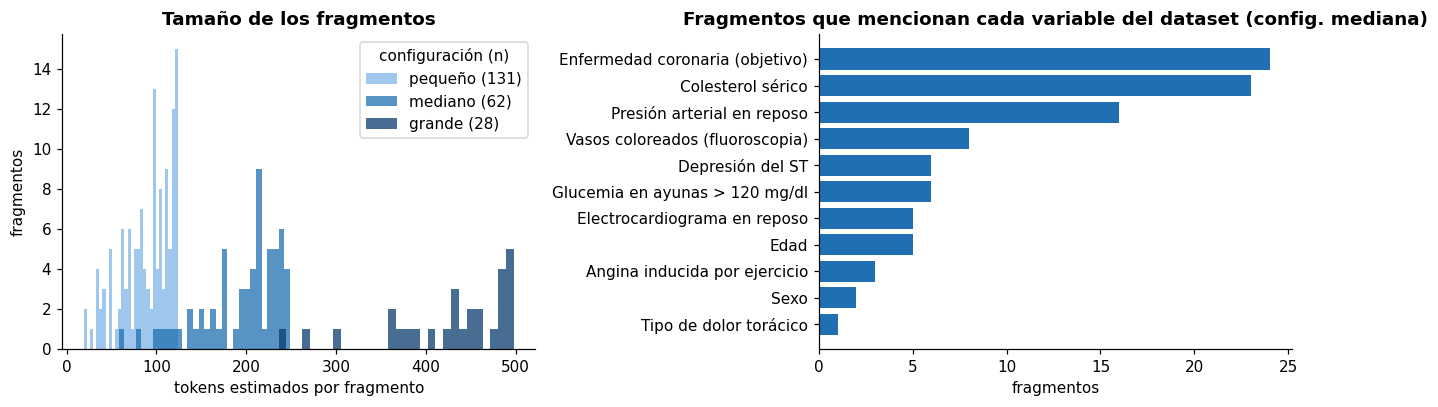

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
colores_config = {"pequeño": "#7fb3e6", "mediano": "#1f6fb2", "grande": "#0b3c6e"}
for nombre, regs in fragmentos.items():
    ejes[0].hist([r["tokens_est"] for r in regs], bins=30, alpha=0.75, color=colores_config[nombre],
                 label=f"{nombre} ({len(regs)})")
ejes[0].set(title="Tamaño de los fragmentos", xlabel="tokens estimados por fragmento", ylabel="fragmentos")
ejes[0].legend(title="configuración (n)")

regs_med = pd.DataFrame(fragmentos["mediano"]).explode("variables").dropna(subset=["variables"])
nombres_var = {d["variable"]: d["nombre"] for d in DICCIONARIO}
cobertura = regs_med.groupby("variables")["chunk_id"].nunique().sort_values()
ejes[1].barh([nombres_var[v] for v in cobertura.index], cobertura.values, color="#1f6fb2")
ejes[1].set(title="Fragmentos que mencionan cada variable del dataset (config. mediana)", xlabel="fragmentos")
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "fig_chunking.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
# Un fragmento de ejemplo con todos sus metadatos (configuración mediana)
ejemplo = next(r for r in fragmentos["mediano"] if len(r["variables"]) >= 2 and r["caracteres"] > 600)
print({k: v for k, v in ejemplo.items() if k != "texto"})
print("\n" + ejemplo["texto"])

{'chunk_id': 'SCA-mediano-0003', 'config': 'mediano', 'doc_id': 'SCA', 'documento': 'Síndrome coronario agudo', 'titulo_documento': 'Guía de síndrome coronario agudo para pacientes y cuidadores (GPC-2013-17)', 'institucion': 'MinSalud · Colciencias', 'anio': 2013, 'url': 'https://www.quindio.gov.co/home/docs/items/item_196/GPC_Ptes_SCA.pdf', 'pagina_inicio': 9, 'pagina_fin': 9, 'seccion': '¿Qué es un Síndrome Coronario Agudo?', 'orden': 3, 'caracteres': 997, 'tokens_est': 249, 'variables': ['age', 'cp', 'oldpeak', 'enfermedad'], 'termina_en_oracion': True}

se produce la aterosclerosis. Cuando además, parte del tejido (trombo) que restringe el canal arterial se desprende taponando la arteria se produce un síndrome coronario agudo. Si la obstrucción es parcial se trata de isquemia o angina de pecho o síndrome coronario agudo sin elevación del ST; y si la obstrucción es total se produce el infarto o síndrome coronario agudo con elevación del ST. También pueden producirse infartos sin tro

## 5. Vectorización con Multilingual-E5

Un modelo de embeddings convierte cada fragmento en un vector que representa su significado: textos con el mismo sentido quedan cerca aunque usen palabras distintas ("tensión alta" e "hipertensión arterial"). Usamos **`intfloat/multilingual-e5-base`**, un modelo abierto de Hugging Face entrenado en más de 100 idiomas, español incluido (Wang et al., 2024). Corre dentro de Colab con la librería Sentence-Transformers (Reimers & Gurevych, 2019): no necesita clave, no tiene cuota y no cuesta nada, como pide la guía del ACA.

Decisiones técnicas:

- **768 dimensiones.** Es la salida nativa del modelo. Cada vector se normaliza a longitud 1, así que la similitud coseno es el producto punto.
- **Consulta y documento.** E5 se entrenó con dos prefijos: `query: ` para preguntas y `passage: ` para documentos. Es el equivalente de `RETRIEVAL_QUERY` y `RETRIEVAL_DOCUMENT` en Gemini Embeddings: el modelo sabe que una pregunta corta debe acercarse a un párrafo que la responde. La sección 6 mide cuánto aporta.
- **Lotes y caché.** Se vectoriza de a 32 textos y cada vector se guarda en `cache/` con una huella del texto. Si se vuelve a ejecutar el notebook, no se repite ningún cálculo.
- **Límite de entrada.** E5 lee hasta 512 tokens por texto y corta lo que sobra. Las configuraciones pequeña y mediana quedan muy por debajo (unos 125 y 250 tokens como máximo); la grande se acerca al límite (unos 500), así que puede perder el final de algunos fragmentos.
- **Comparación con un modelo comercial.** En la sección 8 repetimos la evaluación con OpenAI `text-embedding-3-large` (OpenAI, 2024), recortado a las mismas 768 dimensiones (*Matryoshka Representation Learning*; Kusupati et al., 2022). Sus vectores vienen de la caché incluida en el proyecto, calculados una sola vez por menos de un centavo de dólar; la ejecución normal no llama a esa API.

In [14]:
import openai
from openai import OpenAI

MODELO_LOCAL = "intfloat/multilingual-e5-base"   # modelo abierto: corre en Colab sin clave ni cuota
PRECIO_USD_MILLON = {"text-embedding-3-large": 0.13, "text-embedding-3-small": 0.02}   # lista de precios de OpenAI


class EmbedderBase:
    """Lo común a los modelos: formato por rol, lotes y caché en disco (no se repite ningún cálculo ya hecho)."""
    textos_por_lote = 64
    usa_prefijos = False

    def __init__(self, modelo, dimension, carpeta_cache):
        self.modelo, self.dimension = modelo, dimension
        self.ruta_cache = Path(carpeta_cache) / f"embeddings_{modelo.replace('/', '_')}_{dimension}.npz"
        self.cache = {}
        if self.ruta_cache.exists():
            datos = np.load(self.ruta_cache, allow_pickle=False)
            self.cache = dict(zip(datos["claves"].tolist(), datos["vectores"]))
        self.stats = Counter()
        self.latencias_ms = []

    def formatear(self, texto, rol, titulo=None):
        return texto

    def clave(self, texto_formateado, rol):
        return hashlib.sha256(f"{self.modelo}|{self.dimension}|{rol}|{texto_formateado}".encode()).hexdigest()

    def _guardar_cache(self):
        claves = list(self.cache)
        np.savez_compressed(self.ruta_cache, claves=np.array(claves), vectores=np.stack([self.cache[c] for c in claves]))

    def embed(self, textos, rol="documento", titulos=None, mostrar_progreso=False):
        """Matriz (n, dimension) de vectores normalizados. rol: 'documento', 'consulta' o 'consulta_simple'."""
        titulos = titulos or [None] * len(textos)
        formateados = [self.formatear(t, rol, ti) for t, ti in zip(textos, titulos)]
        claves = [self.clave(f, rol) for f in formateados]
        texto_de = dict(zip(claves, formateados))
        faltan = list(dict.fromkeys(c for c in claves if c not in self.cache))
        self.stats["aciertos_cache"] += sum(c in self.cache for c in claves)
        if faltan:
            lotes = [faltan[i:i + self.textos_por_lote] for i in range(0, len(faltan), self.textos_por_lote)]
            for n, lote in enumerate(lotes, start=1):
                self.cache.update(zip(lote, self._calcular([texto_de[c] for c in lote], rol)))
                self._guardar_cache()
                if mostrar_progreso and (n % 5 == 0 or n == len(lotes)):
                    print(f"  lote {n}/{len(lotes)} · {sum(len(l) for l in lotes[:n])} textos nuevos vectorizados")
        return np.stack([self.cache[c] for c in claves])


class EmbedderOpenAI(EmbedderBase):
    """OpenAI Embeddings: lotes de 64 textos por solicitud, reintentos y conteo real de tokens."""

    def __init__(self, api_key, modelo, dimension, carpeta_cache):
        super().__init__(modelo, dimension, carpeta_cache)
        self.cliente = OpenAI(api_key=api_key, max_retries=0, timeout=60)

    def _calcular(self, textos, rol):
        for intento in range(1, 7):
            t0 = time.perf_counter()
            try:
                respuesta = self.cliente.embeddings.create(model=self.modelo, input=list(textos), dimensions=self.dimension)
            except openai.RateLimitError as e:
                if "insufficient_quota" in str(e) or intento == 6:
                    raise                                   # sin saldo: esperar no sirve
                error, espera = e, min(30, 2 ** intento)
            except (openai.APIConnectionError, openai.APITimeoutError, openai.InternalServerError) as e:
                if intento == 6:
                    raise
                error, espera = e, min(30, 2 ** intento)
            else:
                self.latencias_ms.append((time.perf_counter() - t0) * 1000)
                self.stats["solicitudes_api"] += 1
                self.stats["textos_api"] += len(textos)
                self.stats["tokens_estimados"] += respuesta.usage.total_tokens     # tokens reales facturados
                vectores = [np.asarray(d.embedding, dtype=np.float32) for d in sorted(respuesta.data, key=lambda d: d.index)]
                if len(vectores) != len(textos):
                    raise RuntimeError(f"La API devolvió {len(vectores)} vectores para {len(textos)} textos.")
                return [v / np.linalg.norm(v) for v in vectores]     # normalizados: coseno = producto punto
            self.stats["reintentos"] += 1
            print(f"  {type(error).__name__}: reintento {intento} en {espera} s")
            time.sleep(espera)

    def probar(self):
        return len(self._calcular(["prueba de conexión con el modelo de embeddings"], "consulta")[0])


class EmbedderLocal(EmbedderBase):
    """Modelo abierto multilingüe de Hugging Face que corre dentro de Colab, sin clave ni cuota."""
    textos_por_lote = 32
    usa_prefijos = True

    def __init__(self, nombre, carpeta_cache):
        try:
            from sentence_transformers import SentenceTransformer
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"])
            from sentence_transformers import SentenceTransformer
        self.st = SentenceTransformer(nombre)
        dimension = len(self.st.encode(["prueba"], normalize_embeddings=True)[0])
        super().__init__(nombre, dimension, carpeta_cache)

    def formatear(self, texto, rol, titulo=None):
        # E5 se entrenó con prefijos: "query: " para preguntas y "passage: " para documentos
        if rol == "consulta":
            return f"query: {texto}"
        if rol == "consulta_simple":
            return texto
        return f"passage: {texto}"

    def _calcular(self, textos, rol):
        t0 = time.perf_counter()
        vectores = self.st.encode(list(textos), batch_size=16, normalize_embeddings=True, convert_to_numpy=True)
        self.latencias_ms.append((time.perf_counter() - t0) * 1000)
        self.stats["solicitudes_api"] += 1
        self.stats["textos_api"] += len(textos)
        self.stats["tokens_estimados"] += sum(len(t) for t in textos) // 4 + 1
        return [np.asarray(v, dtype=np.float32) for v in vectores]


CAUSAS = {
    "AuthenticationError": "la clave no es válida: cópiela de nuevo desde platform.openai.com/api-keys (empieza por sk-)",
    "PermissionDeniedError": "la clave no tiene permiso para este modelo o proyecto",
    "NotFoundError": "el modelo no existe para esta cuenta",
    "RateLimitError": "la cuenta no tiene saldo o superó el límite de solicitudes",
}


def crear_embedder():
    if MODELO_EMBEDDINGS.startswith("text-embedding"):
        if OPENAI_API_KEY:
            emb = EmbedderOpenAI(OPENAI_API_KEY, MODELO_EMBEDDINGS, DIMENSION, CARPETA_CACHE)
            try:
                dim = emb.probar()
                print(f"Modelo de embeddings: {MODELO_EMBEDDINGS} (OpenAI) · {dim} dimensiones · conexión OK")
                return emb
            except openai.OpenAIError as e:
                tipo = type(e).__name__
                mensaje = str(e).replace(OPENAI_API_KEY, "***")[:220]
                print(f"✗ OpenAI {MODELO_EMBEDDINGS}: {tipo} · {mensaje}")
                print(f"  Causa probable: {CAUSAS.get(tipo, 'revise la clave y la conexión')}")
        else:
            print("No hay OPENAI_API_KEY.")
        print(f"Se usa {MODELO_LOCAL}, modelo abierto que corre aquí mismo sin clave.")
        nombre = MODELO_LOCAL
    else:
        nombre = MODELO_EMBEDDINGS
    print(f"Cargando {nombre} desde Hugging Face (la primera vez tarda 1 o 2 minutos en descargarse)…")
    emb = EmbedderLocal(nombre, CARPETA_CACHE)
    print(f"Modelo de embeddings: {nombre} · {emb.dimension} dimensiones · listo (sin clave ni cuota)")
    return emb


embedder = crear_embedder()
DIMENSION = embedder.dimension
ES_OPENAI = isinstance(embedder, EmbedderOpenAI)
if ES_OPENAI:
    COLECCION = f"{COLECCION}_openai"   # los vectores de modelos distintos no se mezclan en una colección
print("Colección en Qdrant:", COLECCION)

Cargando intfloat/multilingual-e5-base desde Hugging Face (la primera vez tarda 1 o 2 minutos en descargarse)…


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (6 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Modelo de embeddings: intfloat/multilingual-e5-base · 768 dimensiones · listo (sin clave ni cuota)
Colección en Qdrant: guias_cardio_g13


In [15]:
# Vectorizamos las tres configuraciones de chunking (la comparación de la sección 6 las necesita)
t_inicio = time.perf_counter()
vectores = {}
for nombre, regs in fragmentos.items():
    print(f"Configuración {nombre}: {len(regs)} fragmentos")
    vectores[nombre] = embedder.embed([r["texto"] for r in regs], rol="documento",
                                      titulos=[r["documento"] for r in regs], mostrar_progreso=True)
duracion_embeddings = time.perf_counter() - t_inicio

consumo = pd.DataFrame([{
    "modelo": embedder.modelo, "dimensión": DIMENSION,
    "vectores": sum(len(v) for v in vectores.values()),
    "lotes enviados al modelo": embedder.stats["solicitudes_api"],
    "textos enviados": embedder.stats["textos_api"],
    "tomados de caché": embedder.stats["aciertos_cache"],
    "tokens estimados": embedder.stats["tokens_estimados"],
    "reintentos": embedder.stats["reintentos"],
    "latencia media por lote (ms)": round(np.mean(embedder.latencias_ms)) if embedder.latencias_ms else None,
    "tiempo total (s)": round(duracion_embeddings, 1),
}])
display(consumo)
print("Norma de los vectores (debe ser 1):", np.round(np.linalg.norm(vectores["mediano"][:3], axis=1), 4))

Configuración pequeño: 131 fragmentos
Configuración mediano: 62 fragmentos
Configuración grande: 28 fragmentos


,modelo,dimensión,vectores,lotes enviados al modelo,textos enviados,tomados de caché,tokens estimados,reintentos,latencia media por lote (ms),tiempo total (s)
0,intfloat/multilingual-e5-base,768,221,0,0,221,0,0,None,0.0


Norma de los vectores (debe ser 1): [1. 1. 1.]


## 6. ¿Qué tamaño de fragmento recupera mejor? (justificación del chunking)

Escribimos preguntas en lenguaje natural, como las haría un paciente o un profesional, y para cada una anotamos **en qué documento está la respuesta** y **qué palabras clave debe contener** el fragmento correcto. Un fragmento recuperado cuenta como acierto si viene del documento esperado y contiene al menos una de esas claves.

Métricas:

- **Hit@k**: porcentaje de preguntas con al menos un fragmento correcto entre los *k* primeros.
- **MRR** (*Mean Reciprocal Rank*): promedio de 1/posición del primer fragmento correcto. Vale 1 si siempre aparece de primero, 0,5 si aparece de segundo.
- **Coseno top-1**: similitud del primer resultado. La comparamos con preguntas **fuera del dominio** (que las guías no responden) para saber qué tan bien se separan.

Como los vectores están normalizados, la similitud coseno es el producto punto, así que esta comparación se hace en memoria con NumPy sin gastar recursos del clúster.

In [16]:
# Preguntas de evaluación, redactadas como las haría un paciente. Para cada una anotamos en qué guía está la respuesta
# y palabras clave que debe contener el fragmento correcto (se comparan sin tildes ni mayúsculas).
PREGUNTAS_EVAL = [
    {"pregunta": "¿A partir de qué cifras de presión arterial se considera que una persona tiene hipertensión?",
     "doc_esperado": "HTA", "claves": ["140/90"]},
    {"pregunta": "¿Quiénes tienen más riesgo de desarrollar presión alta?",
     "doc_esperado": "HTA", "claves": ["mayores de 35", "sobrepeso"]},
    {"pregunta": "¿Cuánto baja el riesgo de infarto si reduzco 10 mmHg mi presión sistólica?",
     "doc_esperado": "HTA", "claves": ["25%"]},
    {"pregunta": "¿Cómo sé si el tratamiento para la presión alta me está funcionando?",
     "doc_esperado": "HTA", "claves": ["cerca a 120/80", "tensiometro automatizado"]},
    {"pregunta": "¿Cuál es el síntoma principal de un infarto y en cuánto tiempo debo consultar?",
     "doc_esperado": "SCA", "claves": ["oprime el pecho"]},
    {"pregunta": "¿Para qué me hacen un electrocardiograma si llego a urgencias con dolor en el pecho?",
     "doc_esperado": "SCA", "claves": ["segmento st", "elevacion del st"]},
    {"pregunta": "¿Qué es un stent y para qué se coloca?",
     "doc_esperado": "SCA", "claves": ["stent"]},
    {"pregunta": "¿Qué incluye un programa de rehabilitación cardíaca?",
     "doc_esperado": "SCA", "claves": ["rehabilitacion cardiaca"]},
    {"pregunta": "¿Qué medicamentos debo seguir tomando en casa después de un infarto?",
     "doc_esperado": "SCA", "claves": ["antiagregantes", "terapia dual"]},
    {"pregunta": "¿Cuántas porciones de frutas y verduras debo comer al día para cuidar el corazón?",
     "doc_esperado": "SCA", "claves": ["cinco porciones"]},
    {"pregunta": "¿Cuál es la diferencia entre el colesterol bueno y el colesterol malo?",
     "doc_esperado": "DIS", "claves": ["hdl"]},
    {"pregunta": "¿Tengo que ir en ayunas al examen del colesterol?",
     "doc_esperado": "DIS", "claves": ["ayunas"]},
    {"pregunta": "¿Qué medicamentos se usan para bajar el colesterol?",
     "doc_esperado": "DIS", "claves": ["atorvastatina", "estatinas"]},
    {"pregunta": "¿Qué efectos secundarios pueden dar las estatinas?",
     "doc_esperado": "DIS", "claves": ["dolor muscular", "dolores musculares"]},
    {"pregunta": "Si mi perfil lipídico salió normal, ¿cada cuánto debo repetirlo?",
     "doc_esperado": "DIS", "claves": ["uno a dos anos"]},
]
# Preguntas que las guías no responden: sirven para calibrar el umbral de relevancia
PREGUNTAS_FUERA_DOMINIO = [
    "¿Cuál es la receta tradicional del ajiaco santafereño?",
    "¿Qué documentos necesito para sacar el pasaporte colombiano?",
    "¿Cómo configuro la red wifi de mi casa?",
    "¿Cómo se calcula el IVA de una factura?",
    "¿Cuál es la capital de Australia?",
    "¿Qué equipo ganó el Mundial de fútbol de 2014?",
]
# Preguntas para la demostración (se muestran con sus Top-3)
PREGUNTAS_DEMO = [
    "Siento un dolor fuerte en el pecho que no se me quita, ¿qué debo hacer?",
    "¿Desde qué cifra se considera que uno tiene la tensión alta?",
    "¿Qué alimentos debo evitar si tengo el colesterol alto?",
]
PREGUNTA_FILTRO = {"pregunta": "¿Cuánto ejercicio se recomienda hacer a la semana?", "doc_id": "DIS"}

In [17]:
def es_relevante(registro, pregunta):
    esperados = pregunta["doc_esperado"] if isinstance(pregunta["doc_esperado"], list) else [pregunta["doc_esperado"]]
    if registro["doc_id"] not in esperados:
        return False
    texto = normalizar(registro["texto"])
    return any(normalizar(c) in texto for c in pregunta["claves"])


vec_preguntas = embedder.embed([p["pregunta"] for p in PREGUNTAS_EVAL], rol="consulta")
vec_fuera = embedder.embed(PREGUNTAS_FUERA_DOMINIO, rol="consulta")


def evaluar(regs, matriz, ks=(1, 3, 5)):
    filas = []
    for p, q in zip(PREGUNTAS_EVAL, vec_preguntas):
        sims = matriz @ q
        orden = np.argsort(-sims)
        relevantes = [rank for rank, i in enumerate(orden[:10], start=1) if es_relevante(regs[i], p)]
        primero = relevantes[0] if relevantes else None
        filas.append({"pregunta": p["pregunta"], "doc_esperado": p["doc_esperado"],
                      **{f"hit@{k}": int(primero is not None and primero <= k) for k in ks},
                      "rr": 1 / primero if primero else 0.0, "rank_primer_acierto": primero,
                      "coseno_top1": float(sims[orden[0]]), "doc_top1": regs[orden[0]]["doc_id"]})
    return pd.DataFrame(filas)


evaluaciones, resumen_eval = {}, []
for nombre, regs in fragmentos.items():
    ev = evaluar(regs, vectores[nombre])
    evaluaciones[nombre] = ev
    fuera = (vectores[nombre] @ vec_fuera.T).max(axis=0)
    resumen_eval.append({"configuración": nombre, "fragmentos": len(regs),
                         "hit@1": ev["hit@1"].mean(), "hit@3": ev["hit@3"].mean(), "hit@5": ev["hit@5"].mean(),
                         "MRR": ev["rr"].mean(), "coseno top-1 (dominio)": ev["coseno_top1"].mean(),
                         "coseno top-1 (fuera de dominio)": fuera.mean(),
                         "separación": ev["coseno_top1"].mean() - fuera.mean()})
resumen_eval = pd.DataFrame(resumen_eval).set_index("configuración")
display(resumen_eval.style.format("{:.3f}", subset=[c for c in resumen_eval.columns if c != "fragmentos"])
        .background_gradient(cmap="Blues", subset=["hit@3", "MRR", "separación"]))

# Regla de decisión: mayor MRR; si hay empate (< 0,01), mayor Hit@3 y luego el fragmento más pequeño
orden_config = sorted(CONFIGURACIONES, key=lambda n: (-round(resumen_eval.loc[n, "MRR"], 2),
                                                      -resumen_eval.loc[n, "hit@3"], CONFIGURACIONES[n]["tamano"]))
CONFIG_ELEGIDA = orden_config[0]
print(f"Configuración elegida: {CONFIG_ELEGIDA} ({CONFIGURACIONES[CONFIG_ELEGIDA]['tamano']} caracteres, "
      f"solape {CONFIGURACIONES[CONFIG_ELEGIDA]['solape']})")

,fragmentos,hit@1,hit@3,hit@5,MRR,coseno top-1 (dominio),coseno top-1 (fuera de dominio),separación
configuración,,,,,,,,
pequeño,131,0.933,1.000,1.000,0.956,0.888,0.761,0.127
mediano,62,0.800,1.000,1.000,0.889,0.880,0.760,0.120
grande,28,0.867,1.000,1.000,0.933,0.870,0.752,0.118


Configuración elegida: pequeño (500 caracteres, solape 75)


### ¿Cambia algo la forma de escribir la consulta?

Con E5 la pregunta lleva el prefijo `query: `, el equivalente de `RETRIEVAL_QUERY`. Aquí medimos cuánto aporta repitiendo la evaluación sin él.

In [18]:
efecto_tarea = None
if not embedder.usa_prefijos:
    print(f"{embedder.modelo} vectoriza preguntas y documentos de la misma forma: no hay prefijo de consulta que comparar.")
else:
  vec_simples = embedder.embed([p["pregunta"] for p in PREGUNTAS_EVAL], rol="consulta_simple")
  copia, vec_preguntas = vec_preguntas, vec_simples
  ev_simple = evaluar(fragmentos[CONFIG_ELEGIDA], vectores[CONFIG_ELEGIDA])
  vec_preguntas = copia
  ev_tarea = evaluaciones[CONFIG_ELEGIDA]
  efecto_tarea = pd.DataFrame({
      "con prefijo de consulta": [ev_tarea["hit@1"].mean(), ev_tarea["hit@3"].mean(), ev_tarea["rr"].mean(), ev_tarea["coseno_top1"].mean()],
      "texto de la pregunta solo": [ev_simple["hit@1"].mean(), ev_simple["hit@3"].mean(), ev_simple["rr"].mean(), ev_simple["coseno_top1"].mean()],
  }, index=["hit@1", "hit@3", "MRR", "coseno top-1 medio"])
  efecto_tarea["diferencia"] = efecto_tarea.iloc[:, 0] - efecto_tarea.iloc[:, 1]
  display(efecto_tarea.style.format("{:+.3f}", subset=["diferencia"]).format("{:.3f}", subset=efecto_tarea.columns[:2]))

,con prefijo de consulta,texto de la pregunta solo,diferencia
hit@1,0.933,0.800,+0.133
hit@3,1.000,1.000,+0.000
MRR,0.956,0.889,+0.067
coseno top-1 medio,0.888,0.880,+0.008


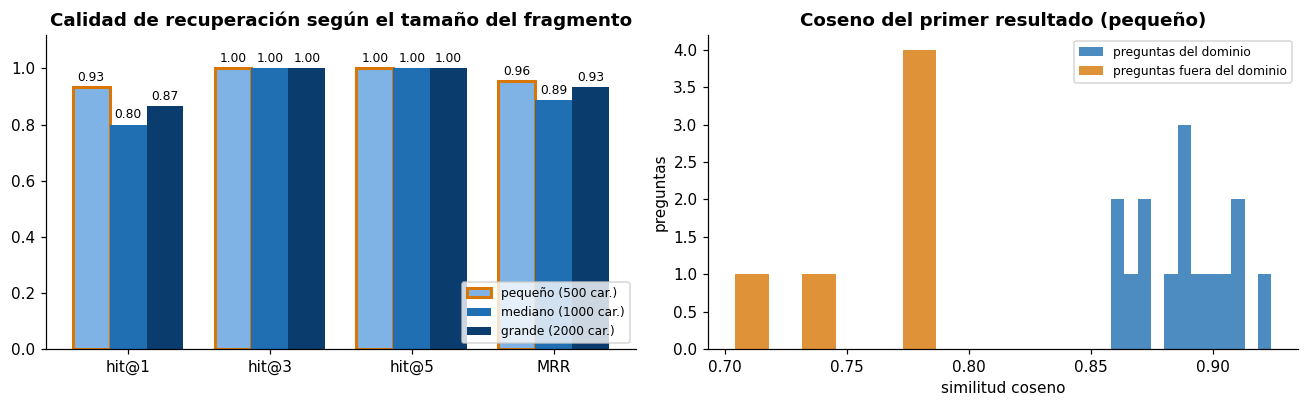

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
metricas = ["hit@1", "hit@3", "hit@5", "MRR"]
x = np.arange(len(metricas))
for j, nombre in enumerate(CONFIGURACIONES):
    valores = resumen_eval.loc[nombre, metricas].values
    barras = ejes[0].bar(x + (j - 1) * 0.26, valores, 0.26, color=colores_config[nombre],
                         label=f"{nombre} ({CONFIGURACIONES[nombre]['tamano']} car.)",
                         edgecolor="#d97706" if nombre == CONFIG_ELEGIDA else "none", linewidth=2)
    ejes[0].bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
ejes[0].set_xticks(x, metricas)
ejes[0].set(ylim=(0, 1.12), title="Calidad de recuperación según el tamaño del fragmento")
ejes[0].legend(fontsize=8, loc="lower right")

ev = evaluaciones[CONFIG_ELEGIDA]
fuera = (vectores[CONFIG_ELEGIDA] @ vec_fuera.T).max(axis=0)
ejes[1].hist(ev["coseno_top1"], bins=12, alpha=0.8, color="#1f6fb2", label="preguntas del dominio")
ejes[1].hist(fuera, bins=6, alpha=0.8, color="#d97706", label="preguntas fuera del dominio")
ejes[1].set(title=f"Coseno del primer resultado ({CONFIG_ELEGIDA})", xlabel="similitud coseno", ylabel="preguntas")
ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "fig_eleccion_chunk.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Aprovisionamiento en Qdrant Cloud y carga por lotes

**Qdrant** es una base de datos vectorial de código abierto; **Qdrant Cloud** la ofrece gestionada. Su capa gratuita es un clúster de 1 nodo con 1 GB de RAM, 0,5 vCPU y 4 GB de disco, suficiente para cerca de un millón de vectores de 768 dimensiones; si pasa una semana sin uso se suspende y se reactiva desde el panel (Qdrant Solutions GmbH, 2024). Elegimos Qdrant porque:

- Guarda cada vector con su **payload** (metadatos JSON) y permite **filtrar** por ellos durante la búsqueda, por ejemplo "solo la guía de hipertensión" o "solo fragmentos que hablen de colesterol".
- Su índice HNSW responde en milisegundos y tiene un panel web donde se ven la colección, los puntos y sus metadatos.

**Métrica de distancia: coseno.** E5 se entrenó comparando vectores por coseno (y OpenAI la recomienda para los suyos); con coseno lo que importa es la dirección del vector (el significado), no su longitud. Qdrant normaliza los vectores al guardarlos, así que el puntaje que devuelve está entre -1 y 1 y es directamente la similitud coseno.

Cada fragmento se sube con un **ID determinista** (UUID v5 calculado del `chunk_id`), de modo que volver a cargar actualiza en vez de duplicar. La carga se hace **por lotes** (`upsert` de 64 puntos) para no enviar todo en una sola solicitud.

In [20]:
from qdrant_client import QdrantClient, models

t0 = time.perf_counter()
if QDRANT_URL:
    qdrant = QdrantClient(url=QDRANT_URL, api_key=QDRANT_API_KEY, timeout=60)
    MODO_QDRANT = "Qdrant Cloud"
else:
    qdrant = QdrantClient(":memory:")
    MODO_QDRANT = "Qdrant en memoria (prueba local)"
colecciones = [c.name for c in qdrant.get_collections().collections]
latencia_conexion = (time.perf_counter() - t0) * 1000
print(f"{MODO_QDRANT} · conexión en {latencia_conexion:.0f} ms · colecciones existentes: {colecciones or 'ninguna'}")

Qdrant Cloud · conexión en 189 ms · colecciones existentes: ['guias_cardio_g13']


In [21]:
def preparar_coleccion(nombre, dimension):
    if qdrant.collection_exists(nombre):
        params = qdrant.get_collection(nombre).config.params.vectors
        if RECREAR_COLECCION or params.size != dimension or params.distance != models.Distance.COSINE:
            qdrant.delete_collection(nombre)
    if not qdrant.collection_exists(nombre):
        qdrant.create_collection(
            collection_name=nombre,
            vectors_config=models.VectorParams(size=dimension, distance=models.Distance.COSINE),
            on_disk_payload=True,            # el texto de los payloads va a disco; la RAM queda para los vectores
        )
    # Índices de payload: hacen eficientes los filtros por documento, variable clínica y página
    for campo, tipo in [("doc_id", models.PayloadSchemaType.KEYWORD),
                        ("variables", models.PayloadSchemaType.KEYWORD),
                        ("pagina_inicio", models.PayloadSchemaType.INTEGER)]:
        qdrant.create_payload_index(collection_name=nombre, field_name=campo, field_schema=tipo)


CAMPOS_PAYLOAD = ["chunk_id", "doc_id", "documento", "titulo_documento", "institucion", "anio", "url",
                  "pagina_inicio", "pagina_fin", "seccion", "orden", "texto", "caracteres", "tokens_est", "variables"]

regs_final = fragmentos[CONFIG_ELEGIDA]
matriz_final = vectores[CONFIG_ELEGIDA]
puntos = [models.PointStruct(id=str(uuid.uuid5(uuid.NAMESPACE_URL, f"cardioguia-g13/{r['chunk_id']}")),
                             vector=v.tolist(),
                             payload={**{c: r[c] for c in CAMPOS_PAYLOAD},
                                      "modelo_embeddings": embedder.modelo, "config_chunking": CONFIG_ELEGIDA})
          for r, v in zip(regs_final, matriz_final)]

preparar_coleccion(COLECCION, DIMENSION)
TAMANO_LOTE = 64
tiempos_lote = []
t0 = time.perf_counter()
for i in range(0, len(puntos), TAMANO_LOTE):
    t_lote = time.perf_counter()
    qdrant.upsert(collection_name=COLECCION, points=puntos[i:i + TAMANO_LOTE], wait=True)
    tiempos_lote.append((time.perf_counter() - t_lote) * 1000)
duracion_carga = time.perf_counter() - t0

info = qdrant.get_collection(COLECCION)
bytes_vectores = len(puntos) * DIMENSION * 4
bytes_payload = sum(len(json.dumps(p.payload, ensure_ascii=False).encode()) for p in puntos)
carga = pd.DataFrame([{
    "destino": MODO_QDRANT, "colección": COLECCION, "puntos": qdrant.count(COLECCION, exact=True).count,
    "lotes": len(tiempos_lote), "ms por lote (mediana)": round(float(np.median(tiempos_lote))),
    "tiempo total (s)": round(duracion_carga, 2), "estado": str(info.status),
    "vectores (MB)": round(bytes_vectores / 1e6, 2), "payload (MB)": round(bytes_payload / 1e6, 2),
    "% de 1 GB de la capa gratuita": round(100 * (bytes_vectores * 1.5 + bytes_payload) / 1e9, 3),
}])
display(carga)
print("Configuración de la colección:", info.config.params.vectors)

,destino,colección,puntos,lotes,ms por lote (mediana),tiempo total (s),estado,vectores (MB),payload (MB),% de 1 GB de la capa gratuita
0,Qdrant Cloud,guias_cardio_g13,131,3,86,0.37,green,0.4,0.13,0.074


Configuración de la colección: size=768 distance=<Distance.COSINE: 'Cosine'> hnsw_config=None quantization_config=None on_disk=None memory=None datatype=None multivector_config=None


## 8. Búsqueda semántica contra el clúster

La función `buscar` sigue el paso 5 de la guía del ACA: recibe una pregunta, la vectoriza con el mismo modelo **en modo consulta** (prefijo `query: `, el equivalente de `RETRIEVAL_QUERY`), busca en Qdrant Cloud por similitud coseno y devuelve los **Top-k** fragmentos con su puntaje, documento, páginas y sección. Opcionalmente filtra por documento o por variable clínica. Estos fragmentos son los que, en el ACA 2, recibirá el modelo de lenguaje para redactar la respuesta.

In [22]:
COLOR_DOC = {d["doc_id"]: d["color"] for d in CORPUS}


def buscar(pregunta, k=TOP_K, doc_id=None, variables=None, con_vectores=False):
    """Top-k fragmentos de Qdrant para una pregunta. Devuelve (DataFrame, tiempos en ms)."""
    t0 = time.perf_counter()
    vector = embedder.embed([pregunta], rol="consulta")[0]
    t1 = time.perf_counter()
    condiciones = []
    if doc_id:
        condiciones.append(models.FieldCondition(key="doc_id", match=models.MatchValue(value=doc_id)))
    if variables:
        condiciones.append(models.FieldCondition(key="variables", match=models.MatchAny(any=list(variables))))
    respuesta = qdrant.query_points(collection_name=COLECCION, query=vector.tolist(), limit=k,
                                    query_filter=models.Filter(must=condiciones) if condiciones else None,
                                    with_payload=True, with_vectors=con_vectores)
    t2 = time.perf_counter()
    filas = [{"rank": i, "score": p.score, **p.payload, "_vector": p.vector}
             for i, p in enumerate(respuesta.points, start=1)]
    return pd.DataFrame(filas), {"ms_embedding": (t1 - t0) * 1000, "ms_qdrant": (t2 - t1) * 1000, "vector": vector}


def mostrar_resultados(pregunta, df, tiempos=None, max_caracteres=420):
    tarjetas = []
    for _, r in df.iterrows():
        texto = r["texto"] if len(r["texto"]) <= max_caracteres else r["texto"][:max_caracteres].rsplit(" ", 1)[0] + " …"
        variables = ", ".join(r["variables"]) if len(r["variables"]) else "—"
        paginas = f"p. {r['pagina_inicio']}" + (f"–{r['pagina_fin']}" if r["pagina_fin"] != r["pagina_inicio"] else "")
        tarjetas.append(f"""
        <div style="border:1px solid #d6dde8;border-left:6px solid {COLOR_DOC.get(r['doc_id'], '#1f6fb2')};
                    border-radius:8px;padding:10px 14px;margin:8px 0;background:#fff;color:#0f172a">
          <div style="display:flex;justify-content:space-between;gap:12px;font-size:13px">
            <b>#{r['rank']} · {r['documento']} · {paginas}</b>
            <span>coseno <b>{r['score']:.4f}</b></span></div>
          <div style="height:6px;background:#e8eef6;border-radius:3px;margin:6px 0">
            <div style="height:6px;width:{max(0, r['score']) * 100:.0f}%;background:#1f6fb2;border-radius:3px"></div></div>
          <div style="font-size:12px;color:#475569">Sección: {r['seccion']} · Variables del dataset: {variables}</div>
          <div style="font-size:13px;margin-top:6px;line-height:1.45">{texto}</div>
        </div>""")
    t = (f"<span style='font-size:12px;color:#475569'>embedding {tiempos['ms_embedding']:.0f} ms · "
         f"búsqueda en Qdrant {tiempos['ms_qdrant']:.0f} ms</span>") if tiempos else ""
    display(HTML(f"<div style='font-family:system-ui,sans-serif;max-width:980px'><p style='margin:4px 0;color:#0f172a'>"
                 f"<b>Pregunta:</b> {pregunta}<br>{t}</p>{''.join(tarjetas)}</div>"))

In [23]:
resultados_demo = {}
for pregunta in PREGUNTAS_DEMO:
    df, tiempos = buscar(pregunta, k=TOP_K)
    resultados_demo[pregunta] = (df, tiempos)
    mostrar_resultados(pregunta, df, tiempos)

### Validación del puntaje: Qdrant calcula exactamente el coseno

Para comprobar que el puntaje de Qdrant es la similitud coseno, pedimos los vectores almacenados y recalculamos el coseno con NumPy:

$$\cos(\mathbf{q}, \mathbf{d}) = \frac{\mathbf{q} \cdot \mathbf{d}}{\lVert \mathbf{q} \rVert \, \lVert \mathbf{d} \rVert}$$

In [24]:
pregunta_val = PREGUNTAS_DEMO[0]
df_val, t_val = buscar(pregunta_val, k=5, con_vectores=True)
q = t_val["vector"]
df_val["coseno_numpy"] = [float(np.dot(q, d) / (np.linalg.norm(q) * np.linalg.norm(d))) for d in df_val["_vector"]]
df_val["diferencia"] = (df_val["score"] - df_val["coseno_numpy"]).abs()
display(df_val[["rank", "documento", "pagina_inicio", "score", "coseno_numpy", "diferencia"]]
        .style.format({"score": "{:.6f}", "coseno_numpy": "{:.6f}", "diferencia": "{:.1e}"}))
print("Diferencia máxima:", f"{df_val['diferencia'].max():.2e}", "→ el puntaje de Qdrant es la similitud coseno.")

,rank,documento,pagina_inicio,score,coseno_numpy,diferencia
0,1,Síndrome coronario agudo,26,0.882795,0.882795,1.6e-07
1,2,Síndrome coronario agudo,9,0.867820,0.867820,3.8e-08
2,3,Síndrome coronario agudo,10,0.862189,0.862189,1.3e-08
3,4,Hipertensión arterial,13,0.857417,0.857417,1.6e-08
4,5,Síndrome coronario agudo,10,0.853063,0.853063,1.4e-08


Diferencia máxima: 1.61e-07 → el puntaje de Qdrant es la similitud coseno.


### Evaluación contra el clúster en la nube

Repetimos la evaluación de la sección 6, ahora con las búsquedas reales en Qdrant Cloud. Deben dar las mismas métricas que el cálculo en memoria; además medimos la latencia de cada consulta.

In [25]:
filas, latencias = [], []
for p in PREGUNTAS_EVAL:
    df, tiempos = buscar(p["pregunta"], k=5)
    latencias.append(tiempos["ms_qdrant"])
    relevantes = [r["rank"] for _, r in df.iterrows() if es_relevante(r, p)]
    primero = relevantes[0] if relevantes else None
    filas.append({"pregunta": p["pregunta"], "documento esperado": p["doc_esperado"],
                  "doc top-1": df.iloc[0]["doc_id"], "coseno top-1": df.iloc[0]["score"],
                  "coseno top-2": df.iloc[1]["score"], "primer acierto": primero,
                  "hit@1": int(primero == 1), "hit@3": int(bool(primero) and primero <= 3),
                  "hit@5": int(bool(primero)), "rr": 1 / primero if primero else 0.0})
eval_nube = pd.DataFrame(filas)
fuera_nube = [buscar(p, k=1)[0].iloc[0]["score"] for p in PREGUNTAS_FUERA_DOMINIO]

metricas_nube = {
    "preguntas": len(eval_nube), "hit@1": eval_nube["hit@1"].mean(), "hit@3": eval_nube["hit@3"].mean(),
    "hit@5": eval_nube["hit@5"].mean(), "MRR": eval_nube["rr"].mean(),
    "coseno top-1 medio (dominio)": eval_nube["coseno top-1"].mean(),
    "coseno top-1 medio (fuera de dominio)": float(np.mean(fuera_nube)),
    "margen top-1 vs top-2": (eval_nube["coseno top-1"] - eval_nube["coseno top-2"]).mean(),
    "latencia Qdrant mediana (ms)": float(np.median(latencias)),
    "latencia Qdrant p95 (ms)": float(np.percentile(latencias, 95)),
}
display(pd.Series(metricas_nube).to_frame("valor").style.format("{:.3f}"))
display(eval_nube.style.format({"coseno top-1": "{:.3f}", "coseno top-2": "{:.3f}", "rr": "{:.2f}"})
        .map(lambda v: "background-color:#fde2e2" if v == 0 else "", subset=["hit@3"]))

,valor
preguntas,15.000
hit@1,0.933
hit@3,1.000
hit@5,1.000
MRR,0.956
coseno top-1 medio (dominio),0.888
coseno top-1 medio (fuera de dominio),0.761
margen top-1 vs top-2,0.021
latencia Qdrant mediana (ms),77.548
latencia Qdrant p95 (ms),87.550


,pregunta,documento esperado,doc top-1,coseno top-1,coseno top-2,primer acierto,hit@1,hit@3,hit@5,rr
0,¿A partir de qué cifras de presión arterial se considera que una persona tiene hipertensión?,HTA,HTA,0.910,0.892,1,1,1,1,1.00
1,¿Quiénes tienen más riesgo de desarrollar presión alta?,HTA,HTA,0.869,0.857,3,0,1,1,0.33
2,¿Cuánto baja el riesgo de infarto si reduzco 10 mmHg mi presión sistólica?,HTA,HTA,0.906,0.844,1,1,1,1,1.00
3,¿Cómo sé si el tratamiento para la presión alta me está funcionando?,HTA,HTA,0.888,0.865,1,1,1,1,1.00
4,¿Cuál es el síntoma principal de un infarto y en cuánto tiempo debo consultar?,SCA,SCA,0.888,0.884,1,1,1,1,1.00
5,¿Para qué me hacen un electrocardiograma si llego a urgencias con dolor en el pecho?,SCA,SCA,0.897,0.870,1,1,1,1,1.00
6,¿Qué es un stent y para qué se coloca?,SCA,SCA,0.873,0.864,1,1,1,1,1.00
7,¿Qué incluye un programa de rehabilitación cardíaca?,SCA,SCA,0.924,0.897,1,1,1,1,1.00
8,¿Qué medicamentos debo seguir tomando en casa después de un infarto?,SCA,SCA,0.880,0.878,1,1,1,1,1.00
9,¿Cuántas porciones de frutas y verduras debo comer al día para cuidar el corazón?,SCA,SCA,0.889,0.851,1,1,1,1,1.00


Hueco entre la pregunta ajena más alta (0.786) y la del dominio más baja (0.858).
Umbral sugerido: coseno ≥ 0.822 (separa correctamente el 100 % de las preguntas)


,pregunta fuera del dominio,coseno top-1
0,¿Cuál es la receta tradicional del ajiaco santafereño?,0.784
1,¿Qué documentos necesito para sacar el pasaporte colombiano?,0.786
2,¿Cómo configuro la red wifi de mi casa?,0.778
3,¿Cómo se calcula el IVA de una factura?,0.779
4,¿Cuál es la capital de Australia?,0.732
5,¿Qué equipo ganó el Mundial de fútbol de 2014?,0.704


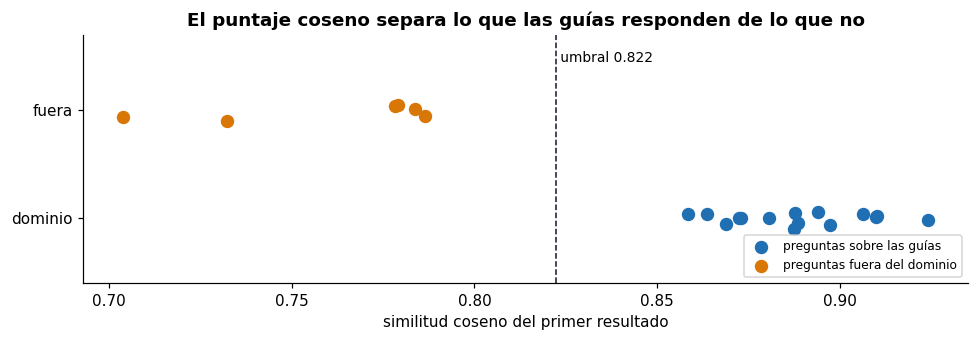

In [26]:
# Umbral de relevancia: el corte de coseno que mejor separa preguntas del dominio de las de fuera del dominio.
# En el ACA 2 servirá para responder "no tengo información suficiente" cuando la pregunta no está en las guías.
dominio, ajenas = eval_nube["coseno top-1"].values, np.array(fuera_nube)
if dominio.min() > ajenas.max():
    # Los dos grupos no se tocan: el umbral va en la mitad del hueco, con el mismo margen hacia cada lado
    UMBRAL_RELEVANCIA = float((dominio.min() + ajenas.max()) / 2)
    mejor = 1.0
    print(f"Hueco entre la pregunta ajena más alta ({ajenas.max():.3f}) y la del dominio más baja ({dominio.min():.3f}).")
else:
    # Los grupos se solapan: se elige el corte que clasifica bien más preguntas
    puntajes = np.r_[dominio, ajenas]
    etiquetas = np.r_[np.ones(len(dominio)), np.zeros(len(ajenas))]
    candidatos = np.unique(np.round(puntajes, 3))
    exactitud = [((puntajes >= u) == etiquetas).mean() for u in candidatos]
    mejor = float(np.max(exactitud))
    UMBRAL_RELEVANCIA = float(np.median([u for u, e in zip(candidatos, exactitud) if e == mejor]))
print(f"Umbral sugerido: coseno ≥ {UMBRAL_RELEVANCIA:.3f} (separa correctamente el {100 * mejor:.0f} % de las preguntas)")
display(pd.DataFrame({"pregunta fuera del dominio": PREGUNTAS_FUERA_DOMINIO, "coseno top-1": ajenas})
        .style.format({"coseno top-1": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.scatter(eval_nube["coseno top-1"], np.zeros(len(eval_nube)) + 0.05 * np.random.default_rng(SEMILLA).standard_normal(len(eval_nube)),
           s=60, color="#1f6fb2", label="preguntas sobre las guías")
ax.scatter(fuera_nube, np.ones(len(fuera_nube)) + 0.05 * np.random.default_rng(SEMILLA).standard_normal(len(fuera_nube)),
           s=60, color="#d97706", label="preguntas fuera del dominio")
ax.axvline(UMBRAL_RELEVANCIA, color="#0f172a", ls="--", lw=1)
ax.text(UMBRAL_RELEVANCIA, 1.45, f" umbral {UMBRAL_RELEVANCIA:.3f}", fontsize=9)
ax.set(yticks=[0, 1], yticklabels=["dominio", "fuera"], ylim=(-0.6, 1.7), xlabel="similitud coseno del primer resultado",
       title="El puntaje coseno separa lo que las guías responden de lo que no")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "fig_umbral.png", dpi=200, bbox_inches="tight")
plt.show()

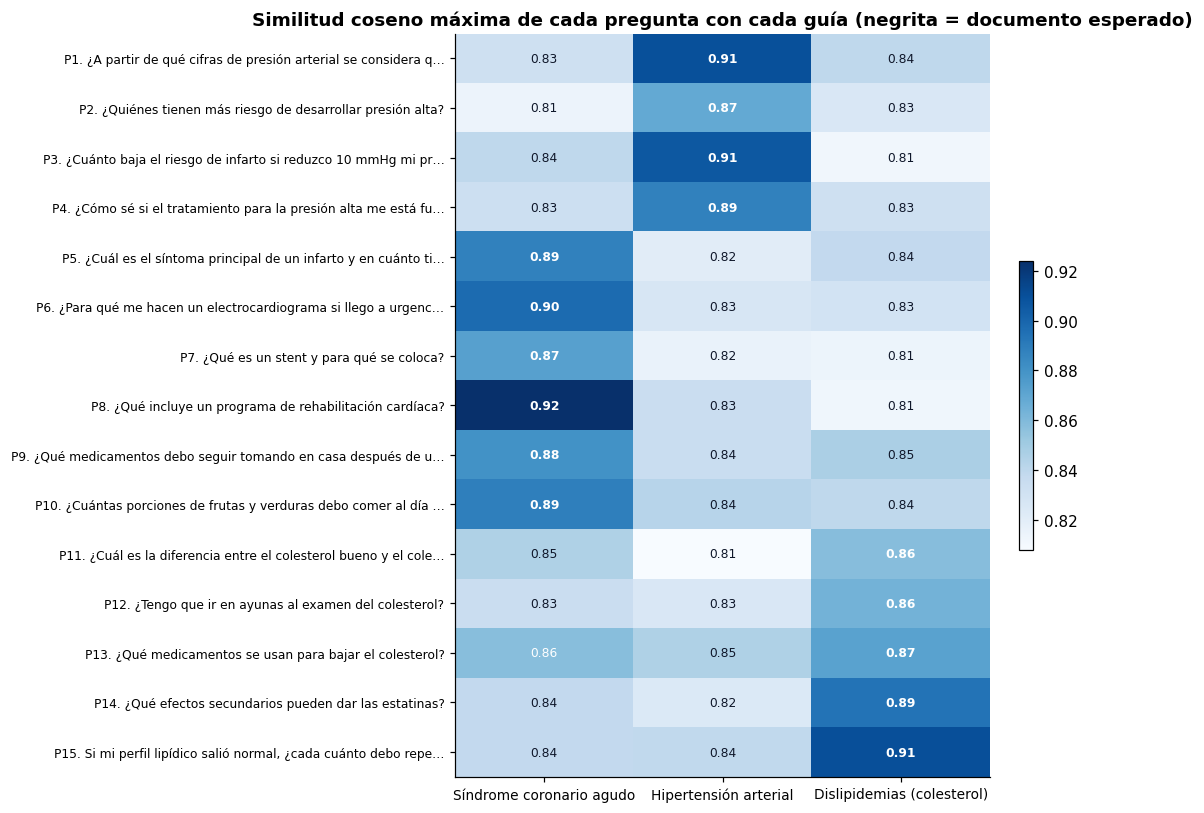

In [27]:
# Mapa de calor: similitud máxima de cada pregunta con cada documento
max_por_doc = pd.DataFrame(
    [{d["titulo_corto"]: float(max((matriz_final[i] @ q) for i, r in enumerate(regs_final) if r["doc_id"] == d["doc_id"]))
      for d in CORPUS} for q in vec_preguntas],
    index=[f"P{i + 1}. {p['pregunta'][:58]}{'…' if len(p['pregunta']) > 58 else ''}" for i, p in enumerate(PREGUNTAS_EVAL)])
fig, ax = plt.subplots(figsize=(10, 0.42 * len(max_por_doc) + 1.2))
im = ax.imshow(max_por_doc.values, cmap="Blues", aspect="auto", vmin=max_por_doc.values.min(), vmax=max_por_doc.values.max())
ax.set_xticks(range(len(max_por_doc.columns)), max_por_doc.columns, rotation=0, fontsize=9)
ax.set_yticks(range(len(max_por_doc)), max_por_doc.index, fontsize=8)
for (i, j), v in np.ndenumerate(max_por_doc.values):
    esperado = CORPUS[j]["doc_id"] in str(PREGUNTAS_EVAL[i]["doc_esperado"])
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
            color="white" if v > max_por_doc.values.mean() else "#0f172a", fontweight="bold" if esperado else "normal")
ax.set_title("Similitud coseno máxima de cada pregunta con cada guía (negrita = documento esperado)")
plt.colorbar(im, ax=ax, fraction=0.025)
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "fig_mapa_calor.png", dpi=200, bbox_inches="tight")
plt.show()

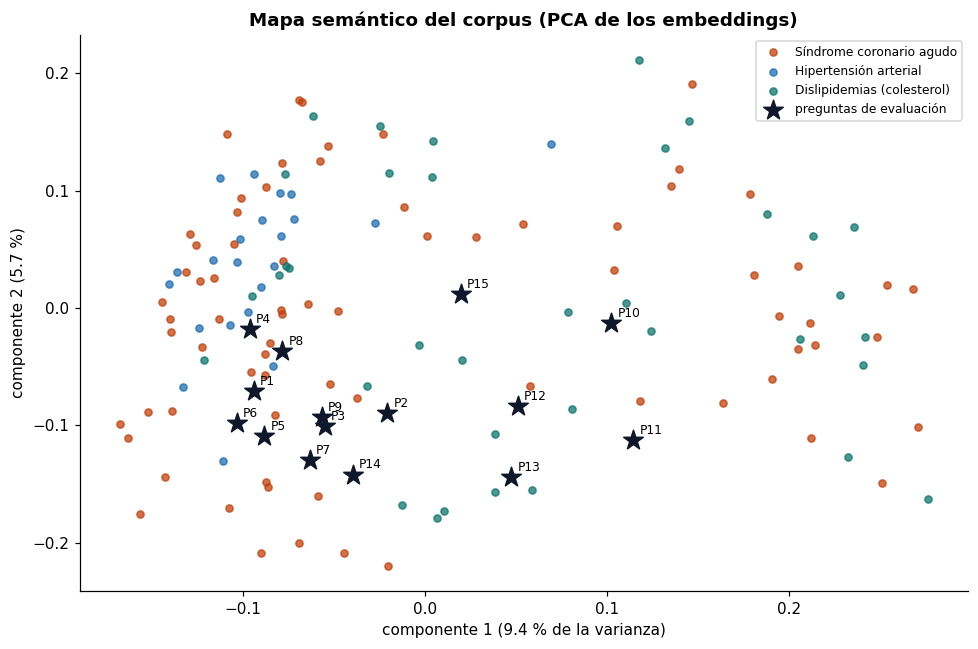

In [28]:
# Mapa semántico: proyección de los vectores en 2D con PCA (cada punto es un fragmento)
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEMILLA).fit(matriz_final)
coords = pca.transform(matriz_final)
coords_q = pca.transform(vec_preguntas)
fig, ax = plt.subplots(figsize=(9, 6))
for d in CORPUS:
    idx = [i for i, r in enumerate(regs_final) if r["doc_id"] == d["doc_id"]]
    ax.scatter(coords[idx, 0], coords[idx, 1], s=22, alpha=0.75, color=d["color"], label=d["titulo_corto"])
ax.scatter(coords_q[:, 0], coords_q[:, 1], marker="*", s=180, color="#0f172a", label="preguntas de evaluación")
for i, (x_, y_) in enumerate(coords_q):
    ax.annotate(f"P{i + 1}", (x_, y_), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(title="Mapa semántico del corpus (PCA de los embeddings)",
       xlabel=f"componente 1 ({100 * pca.explained_variance_ratio_[0]:.1f} % de la varianza)",
       ylabel=f"componente 2 ({100 * pca.explained_variance_ratio_[1]:.1f} %)")
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(CARPETA_SALIDAS / "fig_mapa_semantico.png", dpi=200, bbox_inches="tight")
plt.show()

### Comparación con un modelo comercial: OpenAI `text-embedding-3-large`

¿Cuánto se pierde por usar un modelo abierto y gratuito? Repetimos la evaluación con el modelo de embeddings más grande de OpenAI sobre **los mismos fragmentos y las mismas preguntas**, recortado a 768 dimensiones. Los vectores de OpenAI vienen de la caché `cache/embeddings_text-embedding-3-large_768.npz`, calculada una sola vez; si falta alguno y hay `OPENAI_API_KEY`, se pide a la API. La comparación se hace con NumPy (el coseno es el mismo que calcula Qdrant), para no ocupar la capa gratuita con una segunda colección.

In [29]:
comparacion_modelos, comparacion_detalle, comparacion_tokens, comparacion_origen = None, None, 0, ""


def metricas_modelo(matriz, vq, vf):
    filas = []
    for p, q in zip(PREGUNTAS_EVAL, vq):
        sims = matriz @ q
        orden = np.argsort(-sims)
        relevantes = [rank for rank, i in enumerate(orden[:10], start=1) if es_relevante(regs_final[i], p)]
        primero = relevantes[0] if relevantes else None
        filas.append({"hit@1": int(primero == 1), "hit@3": int(bool(primero) and primero <= 3),
                      "rr": 1 / primero if primero else 0.0, "coseno_top1": float(sims[orden[0]]), "top1": int(orden[0])})
    ev = pd.DataFrame(filas)
    fuera = (matriz @ vf.T).max(axis=0)
    return ev, {"hit@1": ev["hit@1"].mean(), "hit@3": ev["hit@3"].mean(), "MRR": ev["rr"].mean(),
                "coseno top-1 (dominio)": ev["coseno_top1"].mean(), "coseno top-1 (fuera de dominio)": fuera.mean(),
                "separación": ev["coseno_top1"].mean() - fuera.mean()}


comparador = EmbedderOpenAI(OPENAI_API_KEY or "sin-clave", MODELO_COMPARACION, DIMENSION, CARPETA_CACHE)
pedidos = [([r["texto"] for r in regs_final], "documento"), ([p["pregunta"] for p in PREGUNTAS_EVAL], "consulta"),
           (PREGUNTAS_FUERA_DOMINIO, "consulta")]
faltan = sum(comparador.clave(comparador.formatear(t, rol), rol) not in comparador.cache for textos, rol in pedidos for t in textos)
if faltan and not OPENAI_API_KEY:
    print(f"Faltan {faltan} vectores de OpenAI en la caché y no hay OPENAI_API_KEY: se omite la comparación.")
else:
    try:
        m_oa, vq_oa, vf_oa = (comparador.embed(textos, rol=rol) for textos, rol in pedidos)
        comparacion_origen = "caché del proyecto" if not faltan else f"{faltan} vectores pedidos a la API"
        try:
            import tiktoken                       # tokenizador de los modelos text-embedding-3
            codificador = tiktoken.get_encoding("cl100k_base")
            comparacion_tokens = sum(len(codificador.encode(t)) for textos, _ in pedidos for t in textos)
        except Exception:
            comparacion_tokens = sum(len(t) // 4 + 1 for textos, _ in pedidos for t in textos)
            comparacion_origen += " · tokens estimados"
        ev_e5, met_e5 = metricas_modelo(matriz_final, vec_preguntas, vec_fuera)
        ev_oa, met_oa = metricas_modelo(m_oa, vq_oa, vf_oa)
        comparacion_modelos = pd.DataFrame({
            f"{embedder.modelo} (abierto)": {**met_e5, "dónde corre": "Colab, sin clave", "costo (USD)": 0.0},
            f"{MODELO_COMPARACION} (OpenAI)": {**met_oa, "dónde corre": "API de pago",
                                                "costo (USD)": round(comparacion_tokens / 1e6 * PRECIO_USD_MILLON[MODELO_COMPARACION], 4)},
        }).T
        comparacion_detalle = pd.DataFrame({
            "pregunta": [p["pregunta"] for p in PREGUNTAS_EVAL],
            "coseno E5": ev_e5["coseno_top1"], "coseno OpenAI": ev_oa["coseno_top1"],
            "acierto E5": ev_e5["hit@1"], "acierto OpenAI": ev_oa["hit@1"],
            "mismo fragmento top-1": (ev_e5["top1"] == ev_oa["top1"]).astype(int),
        })
        display(comparacion_modelos.style.format({**{c: "{:.3f}" for c in comparacion_modelos.columns
                                                     if c not in ("dónde corre", "costo (USD)")}, "costo (USD)": "{:.4f}"}))
        print(f"Ambos modelos traen el mismo fragmento en primer lugar en {comparacion_detalle['mismo fragmento top-1'].sum()} "
              f"de {len(comparacion_detalle)} preguntas.")
        print("Ojo: el coseno absoluto no se compara entre modelos (cada uno tiene su propia escala); "
              "lo comparable es el acierto (Hit@k, MRR) y la separación entre preguntas del dominio y de fuera.")
    except openai.OpenAIError as e:
        print(f"No se pudo completar la comparación con OpenAI ({type(e).__name__}); el resto del notebook no depende de ella.")

,hit@1,hit@3,MRR,coseno top-1 (dominio),coseno top-1 (fuera de dominio),separación,dónde corre,costo (USD)
intfloat/multilingual-e5-base (abierto),0.933,1.000,0.956,0.888,0.761,0.127,"Colab, sin clave",0.0000
text-embedding-3-large (OpenAI),0.933,1.000,0.967,0.713,0.277,0.436,API de pago,0.0016


Ambos modelos traen el mismo fragmento en primer lugar en 12 de 15 preguntas.
Ojo: el coseno absoluto no se compara entre modelos (cada uno tiene su propia escala); lo comparable es el acierto (Hit@k, MRR) y la separación entre preguntas del dominio y de fuera.


## 9. Búsqueda con filtros e integración SQL + vectorial

**Filtros por metadatos.** La misma pregunta puede limitarse a un documento, o a los fragmentos que hablan de una variable clínica del dataset. Qdrant aplica el filtro durante la búsqueda (no después), así que siempre devuelve *k* resultados que cumplen la condición.

**Consulta híbrida SQL + vector.** Aquí se juntan los dos mundos del proyecto: DuckDB encuentra en el dataset un paciente con varios factores de riesgo; sus valores fuera de rango se convierten en una pregunta en lenguaje natural y en un filtro por variables; Qdrant devuelve las recomendaciones de las guías que corresponden a ese perfil.

In [30]:
pregunta_filtro = PREGUNTA_FILTRO["pregunta"]
df_sin, t_sin = buscar(pregunta_filtro, k=3)
df_con, t_con = buscar(pregunta_filtro, k=3, doc_id=PREGUNTA_FILTRO["doc_id"])
print("Sin filtro:")
mostrar_resultados(pregunta_filtro, df_sin, t_sin, max_caracteres=260)
print(f"Con filtro doc_id = {PREGUNTA_FILTRO['doc_id']}:")
mostrar_resultados(pregunta_filtro, df_con, t_con, max_caracteres=260)

Sin filtro:


Con filtro doc_id = DIS:


In [31]:
REGLAS_ALERTA = {d["variable"]: d["alerta"] for d in DICCIONARIO if d["alerta"] and d["variable"] != "enfermedad"}
casos_sql = " + ".join(f"CASE WHEN {regla} THEN 1 ELSE 0 END" for regla in REGLAS_ALERTA.values())
paciente = con.execute(f"""
    SELECT *, {casos_sql} AS n_alertas
    FROM pacientes
    WHERE enfermedad = 1 AND trestbps >= 140 AND chol >= 240
    ORDER BY n_alertas DESC, trestbps + chol DESC
    LIMIT 1""").df().iloc[0]
alertas = [v for v, regla in REGLAS_ALERTA.items()
           if con.execute(f"SELECT {regla} FROM pacientes WHERE paciente_id = ?", [int(paciente.paciente_id)]).fetchone()[0]]
nombres_alerta = [next(d["nombre"] for d in DICCIONARIO if d["variable"] == v) for v in alertas]
print(f"Paciente {int(paciente.paciente_id)} · {int(paciente.age)} años · {paciente.sexo} · presión {int(paciente.trestbps)} mm Hg · "
      f"colesterol {int(paciente.chol)} mg/dl · {paciente.tipo_dolor} · angina con ejercicio: {'sí' if paciente.exang else 'no'}")
print("Alertas según el diccionario:", ", ".join(nombres_alerta))

consulta_paciente = (f"Paciente de {int(paciente.age)} años con presión arterial de {int(paciente.trestbps)} mm Hg y "
                     f"colesterol total de {int(paciente.chol)} mg/dl con enfermedad coronaria: ¿qué recomiendan las guías "
                     "para controlar la presión arterial, el colesterol y reducir el riesgo cardiovascular?")
filtro_vars = [v for v in alertas if v in ("trestbps", "chol", "fbs", "cp", "exang")]
df_hib, t_hib = buscar(consulta_paciente, k=4, variables=filtro_vars)
print("Filtro de variables en Qdrant:", filtro_vars)
mostrar_resultados(consulta_paciente, df_hib, t_hib, max_caracteres=320)

Paciente 127 · 56 años · Mujer · presión 200 mm Hg · colesterol 288 mg/dl · Asintomático · angina con ejercicio: sí
Alertas según el diccionario: Presión arterial en reposo, Colesterol sérico, Glucemia en ayunas > 120 mg/dl, Electrocardiograma en reposo, Angina inducida por ejercicio, Depresión del ST, Vasos coloreados (fluoroscopia), Gammagrafía con talio
Filtro de variables en Qdrant: ['trestbps', 'chol', 'fbs', 'exang']


### Consulta en vivo

Escriba cualquier pregunta sobre las guías y elija si quiere limitarla a un documento. Cada búsqueda va al clúster de Qdrant Cloud en ese momento (si el widget no aparece, use la celda siguiente).

In [36]:
try:
    import ipywidgets as widgets
    from IPython.display import clear_output

    caja = widgets.Text(placeholder="Ej.: ¿Puedo tomar licor si tuve un infarto?",
                        layout=widgets.Layout(width="65%"))
    selector = widgets.Dropdown(options=[("Todas las guías", None)] + [(d["titulo_corto"], d["doc_id"]) for d in CORPUS],
                                layout=widgets.Layout(width="25%"))
    k_widget = widgets.IntSlider(value=3, min=1, max=8, description="Top-k")
    boton = widgets.Button(description="Buscar en Qdrant Cloud", button_style="primary", icon="search")
    salida = widgets.Output()

    def al_buscar(_):
        with salida:
            clear_output()
            if caja.value.strip():
                df, t = buscar(caja.value.strip(), k=k_widget.value, doc_id=selector.value)
                mostrar_resultados(caja.value.strip(), df, t)

    boton.on_click(al_buscar)
    display(widgets.VBox([widgets.HBox([caja, selector]), widgets.HBox([k_widget, boton]), salida]))
except ImportError:
    print("ipywidgets no está disponible; use la celda siguiente.")

In [33]:
# Alternativa sin widgets: cambie la pregunta y ejecute la celda
mi_pregunta = "¿Qué cuidados debo tener cuando me den de alta después de un infarto?"
df_libre, t_libre = buscar(mi_pregunta, k=3)
mostrar_resultados(mi_pregunta, df_libre, t_libre)

## 10. Consumo y capa gratuita (FinOps)

El objetivo era **costo cero**. Este cuadro resume el consumo real de la ejecución frente a los límites gratuitos de cada servicio. La fila de OpenAI corresponde a la comparación de la sección 8: sus vectores se calcularon una sola vez y quedaron en la caché.

In [34]:
finops = pd.DataFrame([
    {"servicio": ("OpenAI API · " if ES_OPENAI else "Modelo abierto en Colab · ") + embedder.modelo,
     "consumo": f"{embedder.stats['solicitudes_api']} lotes · {embedder.stats['textos_api']} textos · "
                f"{'' if ES_OPENAI else '~'}{embedder.stats['tokens_estimados']:,} tokens".replace(",", "."),
     "control aplicado": ("lotes de 64, 768 dimensiones, reintentos y caché" if ES_OPENAI
                          else "se calcula en el propio Colab, sin cuota"),
     "costo (USD)": round(embedder.stats["tokens_estimados"] / 1e6 * PRECIO_USD_MILLON.get(embedder.modelo, 0), 4)},
    {"servicio": "Qdrant Cloud · Free tier (1 GB RAM)", "consumo": f"{len(puntos)} puntos de {DIMENSION} dims · "
     f"{carga.iloc[0]['% de 1 GB de la capa gratuita']} % de la memoria",
     "control aplicado": f"{DIMENSION} dims{' (Matryoshka)' if ES_OPENAI else ''} y payload en disco",
     "costo (USD)": 0},
    *([{"servicio": "OpenAI API · " + MODELO_COMPARACION + " (solo comparación)",
         "consumo": f"{comparacion_tokens:,} tokens ({comparacion_origen})".replace(",", "."),
         "control aplicado": "calculado una vez y guardado en caché",
         "costo (USD)": round(comparacion_tokens / 1e6 * PRECIO_USD_MILLON[MODELO_COMPARACION], 4)}]
      if comparacion_modelos is not None else []),
    {"servicio": "DuckDB (embebido)", "consumo": f"{len(pacientes)} pacientes · {len(diccionario)} variables",
     "control aplicado": "archivo local, sin servidor", "costo (USD)": 0},
    {"servicio": "Google Colab (CPU)", "consumo": "notebook completo", "control aplicado": "sin GPU", "costo (USD)": 0},
])
display(finops)

,servicio,consumo,control aplicado,costo (USD)
0,Modelo abierto en Colab · intfloat/multilingual-e5-base,0 lotes · 0 textos · ~0 tokens,"se calcula en el propio Colab, sin cuota",0.0000
1,Qdrant Cloud · Free tier (1 GB RAM),131 puntos de 768 dims · 0.074 % de la memoria,768 dims y payload en disco,0.0000
2,OpenAI API · text-embedding-3-large (solo comparación),12.549 tokens (caché del proyecto),calculado una vez y guardado en caché,0.0016
3,DuckDB (embebido),303 pacientes · 13 variables,"archivo local, sin servidor",0.0000
4,Google Colab (CPU),notebook completo,sin GPU,0.0000


In [35]:
# Resumen de resultados (lo usa el póster) y comprimido con las salidas
resumen = {
    "fecha_ejecucion": time.strftime("%Y-%m-%d %H:%M"),
    "modo_qdrant": MODO_QDRANT, "coleccion": COLECCION, "modelo_embeddings": embedder.modelo, "dimension": DIMENSION,
    "corpus": resumen_corpus.to_dict(orient="records"),
    "chunking": comparacion_chunking.to_dict(orient="records"),
    "evaluacion_configs": resumen_eval.reset_index().to_dict(orient="records"),
    "config_elegida": CONFIG_ELEGIDA, "puntos": len(puntos), "carga": carga.to_dict(orient="records")[0],
    "metricas_nube": metricas_nube, "umbral_relevancia": UMBRAL_RELEVANCIA,
    "fuera_nube": dict(zip(PREGUNTAS_FUERA_DOMINIO, map(float, fuera_nube))), "consumo": consumo.to_dict(orient="records")[0],
    "efecto_prefijo_consulta": None if efecto_tarea is None else efecto_tarea.to_dict(), "embeddings_latencia_ms": embedder.latencias_ms,
    "sql": {t: df.to_dict(orient="records") for t, df in resultados_sql.items()},
    "demo": {p: df[["rank", "score", "doc_id", "documento", "pagina_inicio", "pagina_fin", "seccion", "texto"]].to_dict(orient="records")
             for p, (df, _) in resultados_demo.items()},
    "hibrida": {"paciente_id": int(paciente.paciente_id), "alertas": alertas, "consulta": consulta_paciente,
                "resultados": df_hib[["rank", "score", "doc_id", "documento", "pagina_inicio", "seccion", "variables", "texto"]].to_dict(orient="records")},
    "eval_nube": eval_nube.to_dict(orient="records"),
    "comparacion_modelos": None if comparacion_modelos is None else comparacion_modelos.reset_index().to_dict(orient="records"),
    "comparacion_detalle": None if comparacion_modelos is None else comparacion_detalle.to_dict(orient="records"),
}
(CARPETA_SALIDAS / "resumen_resultados.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str),
                                                         encoding="utf-8")
pd.DataFrame(regs_final).drop(columns=["texto"]).to_csv(CARPETA_SALIDAS / "fragmentos_metadatos.csv", index=False)

archivo_resultados = BASE / "resultados_g13.zip"
with zipfile.ZipFile(archivo_resultados, "w", zipfile.ZIP_DEFLATED) as z:
    for carpeta in (CARPETA_SALIDAS, CARPETA_CACHE):
        for ruta in carpeta.glob("*"):
            if ".duckdb" not in ruta.name:
                z.write(ruta, ruta.relative_to(BASE))
print("Resultados guardados en", archivo_resultados.name)
if EN_COLAB:
    from google.colab import files
    files.download(str(archivo_resultados))

Resultados guardados en resultados_g13.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusiones

1. **La arquitectura funciona en la nube y a costo cero.** Las tres guías quedaron en 131 fragmentos, vectorizados con Multilingual-E5 dentro de Colab y cargados en 3 lotes a un clúster gratuito de Qdrant Cloud. Ocupan 0,4 MB de vectores, el 0,07 % de la memoria disponible, y ninguna clave quedó en el código.
2. **El tamaño del fragmento se eligió con evidencia.** Con E5 ganó la configuración pequeña (500 caracteres, solape de 75): MRR de 0,956, frente a 0,933 de la grande y 0,889 de la mediana. Un fragmento corto suele contener una sola idea, y eso facilita que la pregunta lo encuentre.
3. **La búsqueda es precisa contra el clúster.** Las 15 preguntas de evaluación tienen la respuesta correcta entre los 3 primeros resultados, y 14 de ellas en el primero. Qdrant devuelve exactamente la similitud coseno (comprobado con NumPy).
4. **El prefijo de consulta de E5 importa.** Sin `query: `, Hit@1 baja de 0,93 a 0,80: es el equivalente práctico de `RETRIEVAL_QUERY`.
5. **El modelo abierto rinde casi igual que el comercial, pero su escala es distinta.** OpenAI `text-embedding-3-large` logra un MRR de 0,967 frente a 0,956 de E5, con el mismo Hit@3. La diferencia está en el coseno: E5 concentra los puntajes en una franja estrecha (las preguntas ajenas llegan a 0,79 y las del dominio empiezan en 0,86), mientras OpenAI los separa mucho más. Por eso el umbral de E5 se lee en su propia escala, no como un porcentaje de parecido.
6. **Los datos estructurados y los documentos se conectan.** El diccionario de variables etiqueta cada fragmento con los datos clínicos del dataset, lo que permite pasar de un paciente en SQL a las recomendaciones de las guías que corresponden a su perfil.

**Limitaciones.** Las guías para pacientes del MinSalud son de 2013 y 2014; el corpus es pequeño a propósito, por la capa gratuita, y la evaluación usa 15 preguntas redactadas por el equipo. Una de ellas ("¿Quiénes tienen más riesgo de desarrollar presión alta?") recupera el fragmento correcto en tercer lugar con los dos modelos. **Próximo paso (ACA 2):** conectar este recuperador a un modelo de lenguaje con instrucciones de citar la fuente y de usar el umbral para responder "no tengo información suficiente", y publicarlo en Streamlit Community Cloud.

## Referencias

Departamento Administrativo Nacional de Estadística. (2026, 20 de marzo). *En 2025pr disminuyen los nacimientos en Colombia en 4,5 % y aumentan las defunciones en 2,8 %* [Comunicado de prensa]. https://www.dane.gov.co/files/operaciones/EEVV/2026/20-mar-2026/cp-EEVV-Defunciones-IIsem2025pr.pdf

Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1988). *Heart disease* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X

Kusupati, A., Bhatt, G., Rege, A., Wallingford, M., Sinha, A., Ramanujan, V., Howard-Snyder, W., Chen, K., Kakade, S., Jain, P., & Farhadi, A. (2022). Matryoshka representation learning. *Advances in Neural Information Processing Systems, 35*, 30233–30249. https://arxiv.org/abs/2205.13147

Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474. https://arxiv.org/abs/2005.11401

Ministerio de Salud y Protección Social & Colciencias. (2013a). *Guía de práctica clínica hipertensión arterial primaria (HTA): para pacientes y familiares* (Guía No. 18). https://www.minsalud.gov.co/sites/rid/Lists/BibliotecaDigital/RIDE/INEC/IETS/GPC_Ptes_HTA.pdf

Ministerio de Salud y Protección Social & Colciencias. (2013b). *Guía de síndrome coronario agudo para pacientes y cuidadores* (Guía No. GPC-2013-17). https://www.quindio.gov.co/home/docs/items/item_196/GPC_Ptes_SCA.pdf

Ministerio de Salud y Protección Social & Colciencias. (2014). *Guía de práctica clínica para la prevención, detección temprana, diagnóstico, tratamiento y seguimiento de las dislipidemias en la población mayor de 18 años: para pacientes y familiares* (Guía No. 27). https://www.minsalud.gov.co/sites/rid/Lists/BibliotecaDigital/RIDE/INEC/IETS/GPC-Dislipidemia-pacientes.pdf

OpenAI. (2024, 25 de enero). *New embedding models and API updates*. https://openai.com/index/new-embedding-models-and-api-updates/

Qdrant Solutions GmbH. (2024). *Qdrant documentation: Vector search engine & cloud database*. https://qdrant.tech/documentation/

Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing*, 3982–3992. https://arxiv.org/abs/1908.10084

Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (2024). *Multilingual E5 text embeddings: A technical report* (arXiv:2402.05672). arXiv. https://arxiv.org/abs/2402.05672